# Sumativa 2 — Validación, simulación y remuestreo
## Características de navegación y compra en una tienda online

**Grupo 2:** Cristian Hurtado, Jorge Altamirano, Renzo Vilchez y Luis Paredes.  
**Curso:** MCDI501, Estadística Computacional para la Toma de Decisiones.  
**Repositorio:** https://github.com/RenzoVilchez02/proyectoGrupo2

**Pregunta:** ¿qué tan estables son las estimaciones y asociaciones de navegación de S1,
y qué escenarios de compra podemos explorar a partir de sus parámetros?

Este cuaderno continúa explícitamente **S1/Definicion.ipynb**, copia idéntica del notebook
original de F1. No reemplaza sus resultados. Lee su referencia reproducida en
**S1/resultados_s1.json**, identifica las versiones y comprueba los archivos mediante SHA-256.
Las interpretaciones nuevas se calculan desde las salidas, no se anticipa qué será robusto.

### Recorrido y requisitos
| Bloque | Evidencia |
|---|---|
| Referencia S1 | Tres medias e IC t, dos Welch-Holm, Spearman y conversión por visitante |
| Bootstrap | 10.000 remuestras por media, percentil y BCa, comparación y distribuciones |
| Permutación | 10.000 permutaciones por contraste, estadístico Welch y comparación de p |
| Correlaciones | Tres Spearman, 10.000 remuestras emparejadas, IC 95 % y distribuciones |
| Monte Carlo | 10.000 cohortes por escenario, parámetros S1, datos sintéticos y convergencia |
| Robustez | IQR, filas idénticas, jackknife, sensibilidad de correlaciones y de supuestos |
| Insumo S3 | Tabla crítica y un archivo resultados_validados.json |

**Ejecución:** usar la `.venv` existente, reiniciar el kernel y ejecutar todo en orden.
No se necesita internet ni cambiar el kernel del proyecto. Cada bloque tiene un generador
local independiente; volver a ejecutar un bloque no altera la aleatoriedad de los demás.
Las tablas y figuras quedan incorporadas; el único archivo generado por S2 es el JSON final.

## Comprobación del kernel

Ejecute esta primera celda para revisar **Python, ruta del intérprete, las ocho librerías
de requirements.txt y su importación**. Si todo coincide, aparece **ENTORNO CORRECTO**.
Si falta una librería, difiere una versión o falla una importación, se muestran los detalles
y los pasos para seleccionar el entorno correcto. No se instala ni se modifica nada automáticamente.

Una revisión distinta de Python 3.13 o un intérprete ubicado fuera de la .venv generan un aviso;
una versión mayor/menor diferente o dependencias incorrectas detienen la comprobación.


In [1]:
# Comprobación del kernel antes de importar las librerías del análisis.
# Esta celda solo revisa: no instala paquetes ni cambia configuraciones.
from pathlib import Path as _KernelPath
from importlib import metadata as _kernel_metadata
from importlib import import_module as _kernel_importar
import sys as _kernel_sys
import os as _kernel_os

def comprobar_kernel_proyecto():
    inicio = _KernelPath.cwd().resolve()
    raiz = next((p for p in (inicio, *inicio.parents)
                 if (p/'requirements.txt').is_file() and (p/'data/raw').is_dir()), None)
    errores, avisos, paquetes = [], [], []
    python_referencia = (3, 13, 5)
    python_actual = tuple(_kernel_sys.version_info[:3])
    print('COMPROBACIÓN DEL KERNEL — GRUPO 2')
    print('Python actual:', '.'.join(map(str, python_actual)))
    print('Python usado para validar el proyecto: 3.13.5')
    print('Intérprete:', _kernel_sys.executable)
    if raiz is None:
        errores.append('No se encuentra la raíz del proyecto. Abra la carpeta proyectoGrupo2 en VS Code.')
    if python_actual[:2] != python_referencia[:2]:
        errores.append('La versión mayor/menor de Python no coincide con la referencia 3.13.')
    elif python_actual != python_referencia:
        avisos.append('La revisión de Python difiere de 3.13.5; se comprueban también versiones e importaciones.')
    if raiz is not None:
        esperado = raiz/'.venv'/('Scripts/python.exe' if _kernel_os.name == 'nt' else 'bin/python')
        print('Entorno local esperado:', esperado)
        if _kernel_os.path.normcase(str(_KernelPath(_kernel_sys.executable).resolve())) != _kernel_os.path.normcase(str(esperado.resolve())):
            avisos.append('Está usando otro intérprete. Si las versiones e importaciones pasan, puede ser compatible; '
                          'para reproducir el entorno del grupo seleccione la .venv de este proyecto.')
        modulos = {'scikit-learn': 'sklearn'}
        for linea in (raiz/'requirements.txt').read_text(encoding='utf-8').splitlines():
            linea = linea.split('#', 1)[0].strip()
            if '==' not in linea:
                continue
            nombre, requerida = (v.strip() for v in linea.split('==', 1))
            try:
                instalada = _kernel_metadata.version(nombre)
            except _kernel_metadata.PackageNotFoundError:
                instalada = 'NO INSTALADA'
            estado = 'OK' if instalada == requerida else 'REVISAR'
            importacion = 'no comprobada'
            if instalada == requerida:
                try:
                    _kernel_importar(modulos.get(nombre, nombre.replace('-', '_')))
                    importacion = 'OK'
                except Exception as exc:
                    estado = 'ERROR AL IMPORTAR'
                    importacion = f'{type(exc).__name__}: {exc}'
                    errores.append(f'{nombre}: no pudo importarse ({importacion}).')
            else:
                errores.append(f'{nombre}: {instalada}; se requiere {requerida}.')
            paquetes.append({'paquete': nombre, 'instalada': instalada, 'requerida': requerida,
                             'estado': estado, 'importacion': importacion})
        print()
        print(f'{"Librería":<16} {"Instalada":<17} {"Requerida":<13} Estado')
        print('-'*70)
        for fila in paquetes:
            print(f'{fila["paquete"]:<16} {fila["instalada"]:<17} {fila["requerida"]:<13} {fila["estado"]}')
    for aviso in avisos:
        print('AVISO:', aviso)
    if errores:
        print()
        print('ENTORNO CON PROBLEMAS — revise el kernel antes de continuar.')
        for error in errores:
            print(' -', error)
        print('En VS Code: Select Kernel > Select Another Kernel > Python Environments > .venv de Curso 02.')
        print('Después reinicie el kernel y ejecute Run All. Esta celda no instala ni modifica nada.')
    elif avisos:
        print()
        print('LIBRERÍAS CORRECTAS — versiones e importaciones verificadas; revise los avisos del intérprete.')
    else:
        print()
        print('ENTORNO CORRECTO — Python, intérprete y todas las librerías están verificados.')
        print('Puede continuar con el notebook.')
    return {'correcto': not errores, 'errores': errores, 'avisos': avisos,
            'python': '.'.join(map(str, python_actual)), 'interprete': _kernel_sys.executable,
            'paquetes': paquetes}

diagnostico_kernel = comprobar_kernel_proyecto()
if not diagnostico_kernel['correcto']:
    raise RuntimeError('El entorno no coincide con el proyecto. Revise los detalles y pasos indicados arriba.')


COMPROBACIÓN DEL KERNEL — GRUPO 2
Python actual: 3.13.5
Python usado para validar el proyecto: 3.13.5
Intérprete: d:\Magister UNAB\Curso 02 Estadística Computacional\proyectoGrupo2\.venv\Scripts\python.exe
Entorno local esperado: D:\Magister UNAB\Curso 02 Estadística Computacional\proyectoGrupo2\.venv\Scripts\python.exe

Librería         Instalada         Requerida     Estado
----------------------------------------------------------------------
ipykernel        7.3.0             7.3.0         OK
jupyterlab       4.6.3             4.6.3         OK
matplotlib       3.11.2            3.11.2        OK
notebook         7.6.2             7.6.2         OK
numpy            2.5.3             2.5.3         OK
pandas           3.0.5             3.0.5         OK
scikit-learn     1.9.1             1.9.1         OK
scipy            1.18.1            1.18.1        OK

ENTORNO CORRECTO — Python, intérprete y todas las librerías están verificados.
Puede continuar con el notebook.


## 0. Configuración y trazabilidad

Las unidades originales son páginas, segundos y proporciones. Comunicamos duración en minutos
y rebote en porcentaje, con conversiones consistentes en estimaciones e intervalos.
El tamaño de cohorte **N** no es el número de repeticiones **B**. No se confunden datos
artificiales con sesiones reales ni la precisión computacional con la incertidumbre del fenómeno.

In [2]:
from pathlib import Path
from importlib import metadata
from datetime import datetime, timezone
from time import perf_counter
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

def encontrar_raiz(inicio):
    for p in (Path(inicio).resolve(), *Path(inicio).resolve().parents):
        if (p/'data/raw/online_shoppers_intention.csv').is_file() and (p/'S1/resultados_s1.json').is_file():
            return p
    raise FileNotFoundError('Abra el notebook dentro del repositorio con las carpetas S1, S2 y data.')

RAIZ = encontrar_raiz(Path.cwd())
SEED = 20261015
B_BOOT = B_PERM = B_CORR = B_MC = 10_000
ALPHA = .05
CONFIANZA = .95
LOTE = 25
TOL_MC_PP = .1  # margen MC de la media, en puntos porcentuales; decisión de precisión
PRINCIPALES = ['ProductRelated', 'ProductRelated_Duration', 'BounceRates']
FACTORES = {'ProductRelated': 1., 'ProductRelated_Duration': 1/60, 'BounceRates': 100.}
NOMBRES = {'ProductRelated': 'Páginas de productos', 'ProductRelated_Duration': 'Duración en productos (min)',
           'BounceRates': 'Rebote (%)', 'ExitRates': 'Salida (%)'}
COLORES = ['#2f6173', '#b41928', '#b57617', '#64748b']
TIEMPOS = {}
FIGURAS = 0
TABLAS = 0
pd.set_option('display.max_columns', 24)
plt.rcParams.update({'figure.dpi':110, 'font.size':10, 'axes.spines.top':False,
                     'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':.18})

def rng_bloque(numero):
    return np.random.default_rng(np.random.SeedSequence([SEED, int(numero)]))

def numero(x, dec=3):
    return f'{x:,.{dec}f}'.replace(',', '_').replace('.', ',').replace('_', '.')

def tabla(df, titulo):
    global TABLAS
    TABLAS += 1
    display(Markdown(f'**Tabla {TABLAS}. {titulo}**'))
    formatos = {c:(lambda x: numero(x, 4)) for c in df.select_dtypes(include='number').columns
                if not pd.api.types.is_integer_dtype(df[c])}
    display(df.style.format(formatos, na_rep='—').set_properties(**{'white-space':'normal'}))

def figura(texto):
    global FIGURAS
    FIGURAS += 1
    plt.show()
    display(Markdown(f'**Figura {FIGURAS}. {texto}** Fuente: elaboración del grupo con datos UCI.'))

versiones = {p: metadata.version(p) for p in ['numpy','pandas','scipy','matplotlib','ipykernel']}
# El diagnóstico de la primera celda ya comprobó requirements.txt e importaciones.
print('Python:', sys.version.split()[0], '| Semilla:', SEED)
print('Remuestras/permutaciones/iteraciones:', B_BOOT, B_PERM, B_CORR, B_MC)
display(pd.Series(versiones, name='Versión').to_frame())

Python: 3.13.5 | Semilla: 20261015
Remuestras/permutaciones/iteraciones: 10000 10000 10000 10000


,Versión
numpy,2.5.3
pandas,3.0.5
scipy,1.18.1
matplotlib,3.11.2
ipykernel,7.3.0


In [3]:
t0 = perf_counter()
BASE = json.loads((RAIZ/'S1/resultados_s1.json').read_text(encoding='utf-8'))
ARCHIVO = RAIZ/'data/raw/online_shoppers_intention.csv'
HASH_CSV = hashlib.sha256(ARCHIVO.read_bytes()).hexdigest()
HASH_S1 = hashlib.sha256((RAIZ/'S1/Definicion.ipynb').read_bytes()).hexdigest()
# Git puede cambiar CRLF/LF al clonar. Se exige igualdad de contenido normalizado;
# los hashes binarios originales también se conservan para auditoría.
HASH_CSV_LF = hashlib.sha256(ARCHIVO.read_bytes().replace(bytes([13,10]),bytes([10]))).hexdigest()
HASH_S1_LF = hashlib.sha256((RAIZ/'S1/Definicion.ipynb').read_bytes().replace(bytes([13,10]),bytes([10]))).hexdigest()
assert HASH_CSV_LF == BASE['procedencia']['sha256_csv_LF'], 'CSV diferente del utilizado en S1.'
assert HASH_S1_LF == BASE['procedencia']['sha256_notebook_LF'], 'La referencia S1 cambió; revisar trazabilidad.'
if HASH_CSV != BASE['procedencia']['sha256_csv'] or HASH_S1 != BASE['procedencia']['sha256_notebook']:
    print('Diferencia binaria solo de saltos de línea; contenido LF idéntico a S1.')
df = pd.read_csv(ARCHIVO)
for c in ['Revenue','Weekend']:
    normal = df[c].astype(str).str.upper().map({'TRUE':True,'FALSE':False})
    assert normal.notna().all(), f'Categorías inesperadas en {c}'
    df[c] = normal.astype(bool)
assert len(df) == BASE['n'] and int(df.Revenue.sum()) == BASE['compras']
assert df.shape[1] == 18 and not df.isna().any().any()
assert int(df.duplicated().sum()) == BASE['filas_identicas_adicionales']
for c in PRINCIPALES+['ExitRates']:
    assert np.isfinite(df[c]).all() and df[c].ge(0).all()
for c in ['BounceRates','ExitRates']: assert df[c].le(1).all()
base_medias = pd.DataFrame(BASE['estimaciones']).set_index('variable')
base_tests = pd.DataFrame(BASE['pruebas']).set_index('variable')
visitantes = pd.DataFrame(BASE['visitantes']).set_index('VisitorType')

def ic_t(x):
    x = np.asarray(x, dtype=float)
    se = x.std(ddof=1)/np.sqrt(len(x))
    lo, hi = stats.t.interval(CONFIANZA, len(x)-1, loc=x.mean(), scale=se)
    return float(lo), float(hi)

for c in PRINCIPALES:
    r = base_medias.loc[c]
    assert np.isclose(df[c].mean(), r['media'], rtol=1e-12)
    assert np.allclose(ic_t(df[c]), [r['IC95_t_inferior'],r['IC95_t_superior']], rtol=1e-12)
for c in PRINCIPALES[:2]:
    test = stats.ttest_ind(df.loc[df.Revenue,c],df.loc[~df.Revenue,c],equal_var=False)
    assert np.isclose(test.statistic,base_tests.loc[c,'t_Welch'],rtol=1e-12)
    assert np.isclose(test.pvalue,base_tests.loc[c,'p_sin_ajuste'],rtol=1e-10,atol=0)
tabla(pd.DataFrame([{'variable':NOMBRES[c], 'media_S1':base_medias.loc[c,'media']*FACTORES[c],
                    'IC_t_inferior':base_medias.loc[c,'IC95_t_inferior']*FACTORES[c],
                    'IC_t_superior':base_medias.loc[c,'IC95_t_superior']*FACTORES[c]} for c in PRINCIPALES]),
      'Resultados originales de S1 que se validan (mismas unidades en todo S2)')
tabla(visitantes.reset_index(), 'Conteos y conversiones por visitante recuperados de S1')
print(f'{len(df):,} sesiones; {int(df.Revenue.sum()):,} compras; {df.Revenue.mean()*100:.4f}% conversión.')
print('Faltantes: 0. Filas idénticas adicionales:', int(df.duplicated().sum()))
print('Hashes y resultados de S1 verificados; no se eliminan extremos ni filas idénticas.')
TIEMPOS['referencia'] = perf_counter()-t0

**Tabla 1. Resultados originales de S1 que se validan (mismas unidades en todo S2)**

,variable,media_S1,IC_t_inferior,IC_t_superior
0,Páginas de productos,"31,7315","30,9464","32,5166"
1,Duración en productos (min),"19,9124","19,3494","20,4755"
2,Rebote (%),"2,2191","2,1335","2,3047"


**Tabla 2. Conteos y conversiones por visitante recuperados de S1**

,VisitorType,sesiones,compras,sin_compra,porcentaje_compra
0,New_Visitor,1694,422,1272,"24,9115"
1,Other,85,16,69,"18,8235"
2,Returning_Visitor,10551,1470,9081,"13,9323"


12,330 sesiones; 1,908 compras; 15.4745% conversión.
Faltantes: 0. Filas idénticas adicionales: 125
Hashes y resultados de S1 verificados; no se eliminan extremos ni filas idénticas.


## 1. Validación de intervalos mediante bootstrap no paramétrico

Se remuestrean sesiones con reemplazo, con el mismo tamaño original, para las **tres medias de S1**.
Se calculan 10.000 réplicas por variable, IC percentil (cuantiles 2,5 y 97,5 %) y BCa.
BCa ajusta los cuantiles por sesgo mediano (`z0`) y aceleración (`a`), obtenida mediante jackknife.
Para la media, el jackknife tiene una fórmula exacta que evita construir n datasets de tamaño n−1.

El método percentil permite intervalos asimétricos; no exige simetría de la distribución bootstrap.
BCa no es universalmente superior. Ambos dependen de que la distribución empírica y el esquema de
remuestreo representen el proceso de interés. No corrigen por sí solos confusión, sesgo de selección,
dependencia ni errores de medición. Los IC son individuales, no simultáneos.

La independencia se toma como aproximación de S1: la fuente describe usuarios distintos, pero el
CSV no permite comprobar plenamente esa condición. Las muestras se procesan por lotes para limitar memoria.

In [4]:
def bootstrap_medias(x, B, rng, lote=LOTE):
    x = np.asarray(x, dtype=float)
    reps = np.empty(B)
    for inicio in range(0,B,lote):
        cantidad = min(lote,B-inicio)
        idx = rng.integers(0,len(x),size=(cantidad,len(x)))
        reps[inicio:inicio+cantidad] = x[idx].mean(axis=1)
    return reps

def intervalo_bca_media(x, reps):
    x = np.asarray(x,dtype=float)
    theta = x.mean()
    fraccion = (np.count_nonzero(reps < theta)+.5*np.count_nonzero(reps == theta))/len(reps)
    fraccion = np.clip(fraccion,.5/len(reps),1-.5/len(reps))
    z0 = stats.norm.ppf(fraccion)
    # theta_jack=(sum(x)-x)/(n-1); la escala 1/(n-1) se cancela en a.
    delta = x-theta
    a = np.sum(delta**3)/(6*np.sum(delta**2)**1.5)
    z = stats.norm.ppf([ALPHA/2,1-ALPHA/2])
    q = stats.norm.cdf(z0+(z0+z)/(1-a*(z0+z)))
    assert np.isfinite(q).all() and 0 < q[0] < q[1] < 1
    return np.quantile(reps,q), float(z0), float(a)

t0 = perf_counter()
BOOT = {}
filas_boot = []
for i,c in enumerate(PRINCIPALES):
    inicio = perf_counter()
    x = df[c].to_numpy(dtype=float)
    reps = bootstrap_medias(x,B_BOOT,rng_bloque(100+i))
    pct = np.quantile(reps,[.025,.975])
    bca,z0,a = intervalo_bca_media(x,reps)
    f = FACTORES[c]; r = base_medias.loc[c]
    clasico = np.array([r['IC95_t_inferior'],r['IC95_t_superior']])
    BOOT[c] = {'replicas':reps,'percentil':pct,'BCa':bca,'z0':z0,'a':a}
    filas_boot.append({'variable':NOMBRES[c],'n':len(x),'B':B_BOOT,'media_S1':r['media']*f,
        't_inf':clasico[0]*f,'t_sup':clasico[1]*f,'percentil_inf':pct[0]*f,'percentil_sup':pct[1]*f,
        'BCa_inf':bca[0]*f,'BCa_sup':bca[1]*f,'SE_bootstrap':reps.std(ddof=1)*f,'z0':z0,'aceleracion':a,
        'cambio_amplitud_pct_%':100*(np.ptp(pct)/np.ptp(clasico)-1),
        'cambio_amplitud_BCa_%':100*(np.ptp(bca)/np.ptp(clasico)-1)})
    print(c,':',round(perf_counter()-inicio,2),'segundos')
tabla_boot = pd.DataFrame(filas_boot)
tabla(tabla_boot.drop(columns=['z0','aceleracion','cambio_amplitud_pct_%','cambio_amplitud_BCa_%']),
      'Tres medias: comparación de IC t de S1, percentil y BCa del 95 %')
tabla(tabla_boot[['variable','z0','aceleracion','cambio_amplitud_pct_%','cambio_amplitud_BCa_%']],
      'Correcciones BCa y cambio de amplitud frente al IC clásico')
TIEMPOS['bootstrap'] = perf_counter()-t0

ProductRelated : 0.59 segundos
ProductRelated_Duration : 0.59 segundos
BounceRates : 0.57 segundos


**Tabla 3. Tres medias: comparación de IC t de S1, percentil y BCa del 95 %**

,variable,n,B,media_S1,t_inf,t_sup,percentil_inf,percentil_sup,BCa_inf,BCa_sup,SE_bootstrap
0,Páginas de productos,12330,10000,"31,7315","30,9464","32,5166","30,9600","32,5156","30,9650","32,5222","0,3976"
1,Duración en productos (min),12330,10000,"19,9124","19,3494","20,4755","19,3621","20,4923","19,3677","20,4965","0,2878"
2,Rebote (%),12330,10000,"2,2191","2,1335","2,3047","2,1357","2,3040","2,1369","2,3056","0,0429"


**Tabla 4. Correcciones BCa y cambio de amplitud frente al IC clásico**

,variable,z0,aceleracion,cambio_amplitud_pct_%,cambio_amplitud_BCa_%
0,Páginas de productos,"-0,0044","0,0065","-0,9330","-0,8289"
1,Duración en productos (min),"-0,0113","0,0109","0,3681","0,2444"
2,Rebote (%),"0,0103","0,0044","-1,6948","-1,4875"


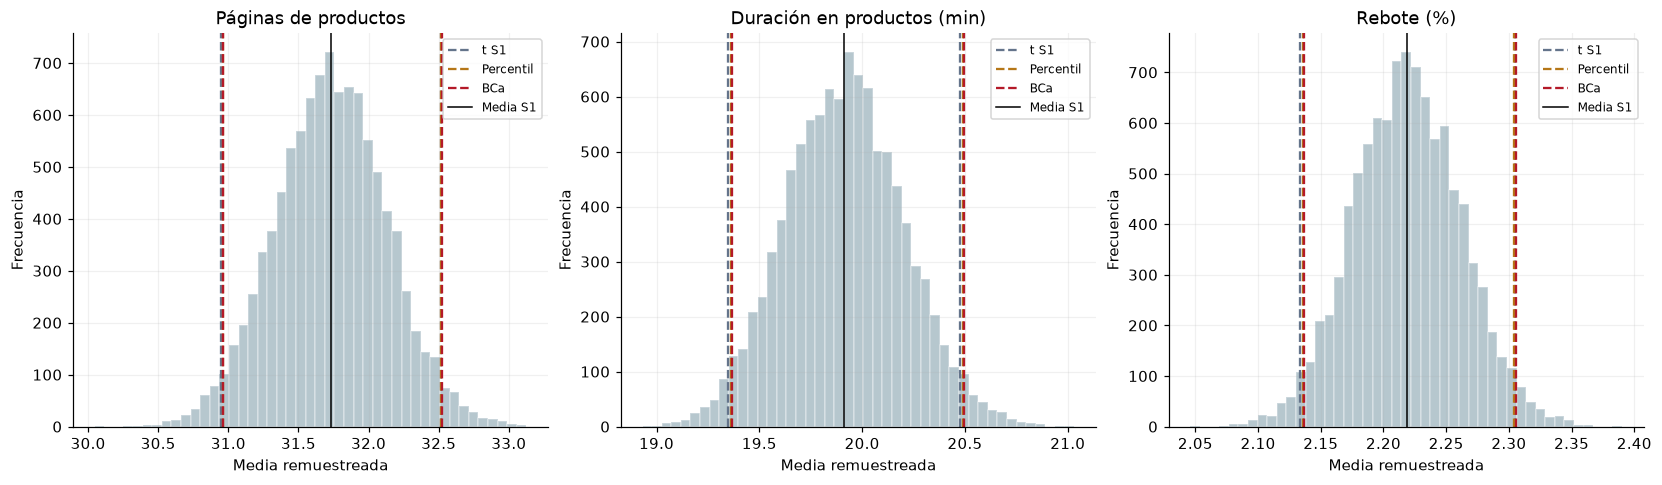

**Figura 1. Distribuciones bootstrap de las tres medias y comparación de intervalos individuales del 95 %.** Fuente: elaboración del grupo con datos UCI.

**Páginas de productos:** amplitud percentil frente a t: **-0,93 %**; BCa frente a t: **-0,83 %**. BCa = **[30,965; 32,522]**. Respecto de t, el límite inferior BCa se desplaza **0,0186** y el superior **0,0056**, en las unidades de la variable.

**Duración en productos (min):** amplitud percentil frente a t: **0,37 %**; BCa frente a t: **0,24 %**. BCa = **[19,368; 20,497]**. Respecto de t, el límite inferior BCa se desplaza **0,0183** y el superior **0,0210**, en las unidades de la variable.

**Rebote (%):** amplitud percentil frente a t: **-1,69 %**; BCa frente a t: **-1,49 %**. BCa = **[2,137; 2,306]**. Respecto de t, el límite inferior BCa se desplaza **0,0034** y el superior **0,0008**, en las unidades de la variable.

**Conclusión de la validación bootstrap.** Los cambios absolutos de amplitud frente a t son menores al 2 % en las tres medias (máximo observado: 1,69 %). Los desplazamientos de los extremos se presentan arriba para evaluar también la posición, no solo el ancho. En esta muestra grande, la proximidad observada entre t, percentil y BCa respalda estabilidad de los intervalos de las medias frente al método de construcción. No hay evidencia en esta comparación para preferir automáticamente BCa por el solo hecho de que los datos individuales sean asimétricos. Se conserva el IC t como referencia de S1 y se presentan los dos IC bootstrap como comprobación. Esta concordancia no elimina la sensibilidad de las medias a las colas ni los supuestos de independencia y representatividad; ambos aspectos se revisan en robustez.

In [5]:
fig,axes = plt.subplots(1,3,figsize=(15,4.3),constrained_layout=True)
for ax,c in zip(axes,PRINCIPALES):
    f=FACTORES[c]; b=BOOT[c]; r=base_medias.loc[c]
    ax.hist(b['replicas']*f,bins=45,color=COLORES[0],alpha=.35,edgecolor='white')
    for limites,color,nombre in [([r['IC95_t_inferior'],r['IC95_t_superior']],COLORES[3],'t S1'),
                                  (b['percentil'],COLORES[2],'Percentil'),(b['BCa'],COLORES[1],'BCa')]:
        ax.axvline(limites[0]*f,color=color,ls='--',label=nombre)
        ax.axvline(limites[1]*f,color=color,ls='--')
    ax.axvline(r['media']*f,color='black',lw=1,label='Media S1')
    ax.set(title=NOMBRES[c],xlabel='Media remuestreada',ylabel='Frecuencia'); ax.legend(fontsize=8)
figura('Distribuciones bootstrap de las tres medias y comparación de intervalos individuales del 95 %.')
for _,r in tabla_boot.iterrows():
    display(Markdown(f"**{r['variable']}:** amplitud percentil frente a t: **{numero(r['cambio_amplitud_pct_%'],2)} %**; "
                     f"BCa frente a t: **{numero(r['cambio_amplitud_BCa_%'],2)} %**. "
                     f"BCa = **[{numero(r.BCa_inf)}; {numero(r.BCa_sup)}]**. "
                     f"Respecto de t, el límite inferior BCa se desplaza **{numero(r.BCa_inf-r.t_inf,4)}** "
                     f"y el superior **{numero(r.BCa_sup-r.t_sup,4)}**, en las unidades de la variable."))

# Conclusión obtenida de las comparaciones, no de una preferencia previa por BCa.
max_cambio_amplitud = float(tabla_boot[['cambio_amplitud_pct_%','cambio_amplitud_BCa_%']].abs().to_numpy().max())
if max_cambio_amplitud < 2:
    lectura_amplitud = (f'Los cambios absolutos de amplitud frente a t son menores al 2 % en las tres medias '
                       f'(máximo observado: {numero(max_cambio_amplitud,2)} %). ')
else:
    lectura_amplitud = (f'El mayor cambio absoluto de amplitud frente a t es {numero(max_cambio_amplitud,2)} %. '
                       'Las diferencias requieren interpretación por variable. ')
interpretacion_bootstrap = (
    lectura_amplitud +
    'Los desplazamientos de los extremos se presentan arriba para evaluar también la posición, no solo el ancho. '
    'En esta muestra grande, la proximidad observada entre t, percentil y BCa respalda estabilidad de los '
    'intervalos de las medias frente al método de construcción. No hay evidencia en esta comparación '
    'para preferir automáticamente BCa por el solo hecho de que los datos individuales sean asimétricos. '
    'Se conserva el IC t como referencia de S1 y se presentan los dos IC bootstrap como comprobación. '
    'Esta concordancia no elimina la sensibilidad de las medias a las colas ni los supuestos de '
    'independencia y representatividad; ambos aspectos se revisan en robustez.')
display(Markdown('**Conclusión de la validación bootstrap.** '+interpretacion_bootstrap))


## 2. Validación de dos pruebas mediante permutación

Se mantienen las hipótesis bilaterales de S1: para páginas y duración, **H₀: μ con compra = μ sin compra**;
**H₁: las medias difieren**. α = 0,05, con Holm sobre la familia de dos contrastes.

Se permutan las etiquetas manteniendo los tamaños de ambos grupos. Debido a varianzas y tamaños
desiguales, se utiliza el **estadístico t de Welch**, recalculando su denominador en cada permutación.
La permutación es exacta bajo intercambiabilidad (igualdad de distribuciones); para la hipótesis débil
de igualdad de medias con distribuciones diferentes, la estandarización ofrece una justificación
asintótica bajo condiciones regulares, no una prueba finita exacta sin supuestos.

Se calcula p bilateral como `(1 + número de |t_perm| ≥ |t_observado|)/(B + 1)`.
Con 10.000 permutaciones, la resolución mínima es 1/10.001. No se reporta p = 0 ni se intenta
reproducir numéricamente valores paramétricos del orden de 10⁻⁴³. Un IC binomial del conteo de
excedencias describe precisión Monte Carlo de la cola, no un IC del efecto.

In [6]:
def holm(p):
    p=np.asarray(p,dtype=float); orden=np.argsort(p)
    ajustados=np.empty(len(p))
    ajustados[orden]=np.minimum(1,np.maximum.accumulate((len(p)-np.arange(len(p)))*p[orden]))
    return ajustados

def intervalo_wilson(k,n):
    z=stats.norm.ppf(.975); p=k/n; den=1+z*z/n
    centro=(p+z*z/(2*n))/den
    ancho=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return max(0.,centro-ancho),min(1.,centro+ancho)

def permutar_welch(x,grupo,B,rng):
    x=np.asarray(x,dtype=float); n=len(x); n1=int(np.sum(grupo)); n0=n-n1
    total=x.sum(); total2=np.sum(x*x); valores=np.empty(B)
    for b in range(B):
        seleccion=rng.choice(n,size=n1,replace=False)
        xs=x[seleccion]; suma=xs.sum(); suma2=np.sum(xs*xs)
        m1=suma/n1; m0=(total-suma)/n0
        v1=max(0.,(suma2-suma*suma/n1)/(n1-1))
        v0=max(0.,((total2-suma2)-(total-suma)**2/n0)/(n0-1))
        valores[b]=(m1-m0)/np.sqrt(v1/n1+v0/n0)
    return valores

t0=perf_counter(); PERM={}; filas_perm=[]
for i,c in enumerate(PRINCIPALES[:2]):
    observado=float(base_tests.loc[c,'t_Welch'])
    valores=permutar_welch(df[c],df.Revenue,B_PERM,rng_bloque(200+i))
    k=int(np.count_nonzero(np.abs(valores)>=abs(observado)))
    p=(k+1)/(B_PERM+1); li,ls=intervalo_wilson(k,B_PERM)
    PERM[c]=valores
    filas_perm.append({'variable':NOMBRES[c],'B':B_PERM,'t_S1':observado,
                      'diferencia_S1':base_tests.loc[c,'diferencia_con_menos_sin']*FACTORES[c],
                      'p_Welch_S1':base_tests.loc[c,'p_sin_ajuste'],'p_Holm_S1':base_tests.loc[c,'p_Holm'],
                      'excedencias':k,'p_permutacion':p,'cola_MC_Wilson_inf':li,'cola_MC_Wilson_sup':ls})
tabla_perm=pd.DataFrame(filas_perm)
tabla_perm['p_perm_Holm']=holm(tabla_perm.p_permutacion)
tabla_perm['decision_perm']=np.where(tabla_perm.p_perm_Holm<ALPHA,'Rechazar H₀','No rechazar H₀')
tabla_perm['concordancia_S1']=((tabla_perm.p_perm_Holm<ALPHA).to_numpy()==(base_tests.p_Holm<ALPHA).to_numpy())
tabla(tabla_perm.drop(columns=['p_Welch_S1','p_Holm_S1']), 'Permutación estandarizada: resultados y resolución Monte Carlo')
display(tabla_perm[['variable','p_Welch_S1','p_Holm_S1','p_permutacion','p_perm_Holm']].style.format({
    c:'{:.6e}' for c in ['p_Welch_S1','p_Holm_S1','p_permutacion','p_perm_Holm']}))
TIEMPOS['permutacion']=perf_counter()-t0

**Tabla 5. Permutación estandarizada: resultados y resolución Monte Carlo**

,variable,B,t_S1,diferencia_S1,excedencias,p_permutacion,cola_MC_Wilson_inf,cola_MC_Wilson_sup,p_perm_Holm,decision_perm,concordancia_S1
0,Páginas de productos,10000,"14,0017","19,4955",0,"0,0001","0,0000","0,0004","0,0002",Rechazar H₀,True
1,Duración en productos (min),10000,"14,4470","13,4370",0,"0,0001","0,0000","0,0004","0,0002",Rechazar H₀,True


,variable,p_Welch_S1,p_Holm_S1,p_permutacion,p_perm_Holm
0,Páginas de productos,8.834785e-43,8.834785e-43,9.999000e-05,1.999800e-04
1,Duración en productos (min),2.173791e-45,4.347582e-45,9.999000e-05,1.999800e-04


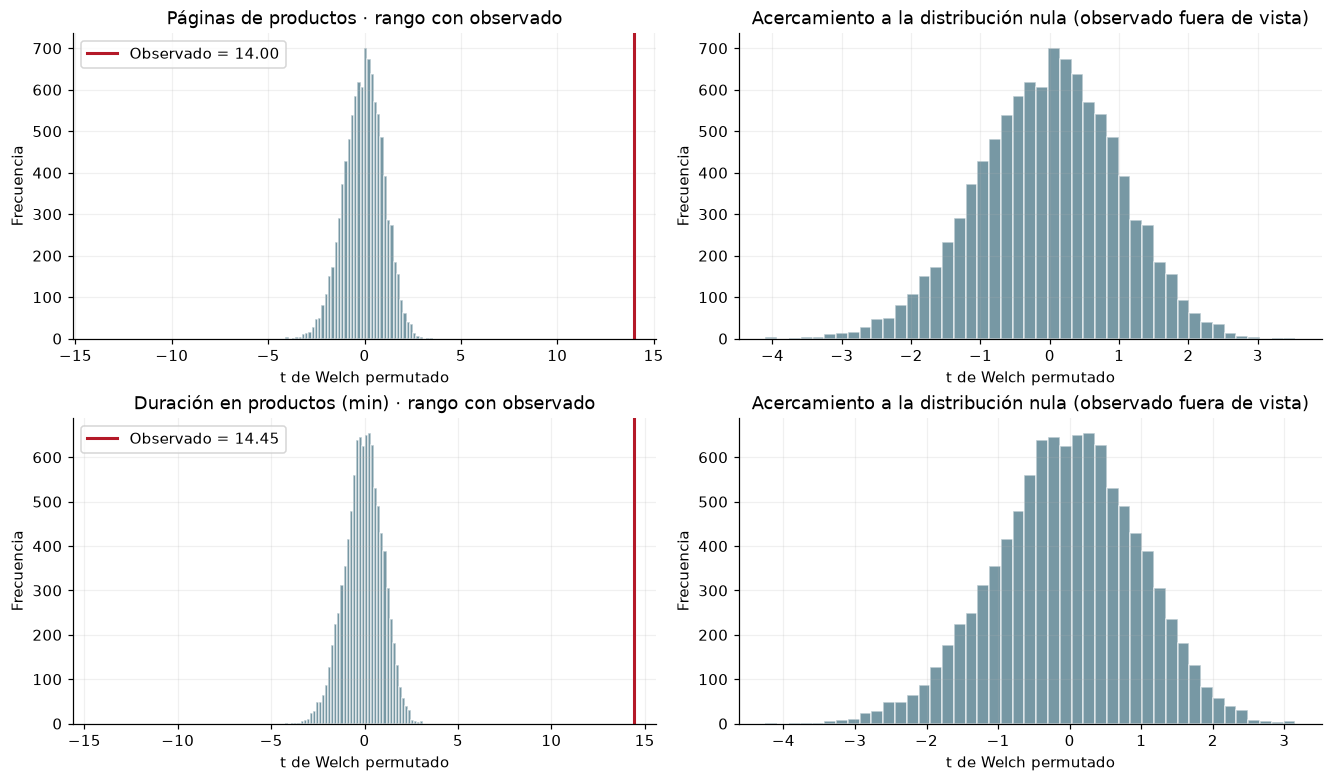

**Figura 2. Distribuciones nulas de permutación, estadísticos observados y acercamientos explícitos.** Fuente: elaboración del grupo con datos UCI.

**Lectura:** concordancia con S1 en **2 de 2 contrastes**. Si no hay excedencias, el resultado indica una cola muy pequeña a la resolución de este experimento; no equivale a probabilidad cero. Las pruebas mantienen sus limitaciones de independencia y ausencia de causalidad.

**Elección metodológica para este estudio.** Conservamos Welch como contraste principal de S1 porque responde a diferencias de medias entre grupos independientes sin exigir igualdad de varianzas y ambos grupos son grandes. La permutación estandarizada funciona aquí como comprobación complementaria de la decisión frente a otra aproximación de la distribución nula; no se considera automáticamente superior. Las decisiones coinciden en 2 de 2 contrastes. La resolución mínima de p en esta simulación es 9.999e-05; no permite reproducir numéricamente los p paramétricos extremadamente pequeños ni implica que ambos p sean iguales. La interpretación de la permutación sigue condicionada a la intercambiabilidad para exactitud o a la aproximación asintótica de la prueba estandarizada cuando solo se supone igualdad de medias. Ninguno de los procedimientos resuelve dependencia, confusión o falta de asignación aleatoria; la conclusión es asociativa y la magnitud debe leerse junto a su sensibilidad.

In [7]:
fig,axes=plt.subplots(2,2,figsize=(12,7),constrained_layout=True)
for i,c in enumerate(PRINCIPALES[:2]):
    valores=PERM[c]; obs=base_tests.loc[c,'t_Welch']
    for j in range(2):
        ax=axes[i,j]; ax.hist(valores,bins=45,color=COLORES[0],alpha=.65,edgecolor='white')
        ax.set(xlabel='t de Welch permutado',ylabel='Frecuencia')
    axes[i,0].axvline(obs,color=COLORES[1],lw=2,label=f'Observado = {obs:.2f}')
    axes[i,0].set_xlim(min(valores.min(),-abs(obs))*1.08,max(valores.max(),abs(obs))*1.08)
    axes[i,0].set_title(NOMBRES[c]+' · rango con observado'); axes[i,0].legend()
    axes[i,1].set_title('Acercamiento a la distribución nula (observado fuera de vista)')
figura('Distribuciones nulas de permutación, estadísticos observados y acercamientos explícitos.')
display(Markdown('**Lectura:** concordancia con S1 en **'+str(int(tabla_perm.concordancia_S1.sum()))+
                 ' de 2 contrastes**. Si no hay excedencias, el resultado indica una cola muy pequeña '
                 'a la resolución de este experimento; no equivale a probabilidad cero. '
                 'Las pruebas mantienen sus limitaciones de independencia y ausencia de causalidad.'))

interpretacion_permutacion = (
    'Conservamos Welch como contraste principal de S1 porque responde a diferencias de medias '
    'entre grupos independientes sin exigir igualdad de varianzas y ambos grupos son grandes. '
    'La permutación estandarizada funciona aquí como comprobación complementaria de la decisión '
    'frente a otra aproximación de la distribución nula; no se considera automáticamente superior. '
    f'Las decisiones coinciden en {int(tabla_perm.concordancia_S1.sum())} de {len(tabla_perm)} contrastes. '
    f'La resolución mínima de p en esta simulación es {1/(B_PERM+1):.6g}; no permite reproducir '
    'numéricamente los p paramétricos extremadamente pequeños ni implica que ambos p sean iguales. '
    'La interpretación de la permutación sigue condicionada a la intercambiabilidad para exactitud '
    'o a la aproximación asintótica de la prueba estandarizada cuando solo se supone igualdad de medias. '
    'Ninguno de los procedimientos resuelve dependencia, confusión o falta de asignación aleatoria; '
    'la conclusión es asociativa y la magnitud debe leerse junto a su sensibilidad.')
display(Markdown('**Elección metodológica para este estudio.** '+interpretacion_permutacion))


## 3. Estabilidad de tres correlaciones de Spearman

Se recuperan tres asociaciones de S1. Se remuestrean **filas emparejadas**, no columnas por separado,
con 10.000 remuestras por relación e IC percentil del 95 %. Spearman se recalcula en cada remuestra,
incluidos sus empates; no se remuestrean rangos fijos de la muestra original.

Para acelerar sin cambiar el estimador, se representan las repeticiones de cada fila por sus
multiplicidades y se recalculan rangos medios ponderados. Se verifica su equivalencia frente a
`scipy.stats.spearmanr` sobre una remuestra explícita. Se evalúan amplitud, signo y sensibilidad,
no solo si el intervalo excluye cero. Son intervalos individuales, no simultáneos.

In [8]:
PARES=[('ProductRelated','ProductRelated_Duration'),('BounceRates','ExitRates'),('ProductRelated','ExitRates')]

def codigos_ordenados(x):
    unicos,inversa=np.unique(np.asarray(x),return_inverse=True)
    return inversa,len(unicos)

def spearman_multiplicidades(pesos,ix,kx,iy,ky):
    n=pesos.sum(); centro=(n+1)/2
    fx=np.bincount(ix,weights=pesos,minlength=kx)
    fy=np.bincount(iy,weights=pesos,minlength=ky)
    rx=(np.cumsum(fx)-(fx-1)/2)[ix]-centro
    ry=(np.cumsum(fy)-(fy-1)/2)[iy]-centro
    den=np.sqrt(np.sum(pesos*rx*rx)*np.sum(pesos*ry*ry))
    return np.sum(pesos*rx*ry)/den if den else np.nan

t0=perf_counter(); CORR={}; filas_corr=[]; n=len(df)
for i,(cx,cy) in enumerate(PARES):
    x=df[cx].to_numpy(); y=df[cy].to_numpy()
    ix,kx=codigos_ordenados(x); iy,ky=codigos_ordenados(y)
    rng=rng_bloque(300+i); chequeo=rng.integers(0,n,n)
    pesos=np.bincount(chequeo,minlength=n)
    assert np.isclose(spearman_multiplicidades(pesos,ix,kx,iy,ky),
                      stats.spearmanr(x[chequeo],y[chequeo]).statistic,rtol=1e-12)
    original=float(BASE['correlaciones_spearman'][cx][cy])
    assert np.isclose(stats.spearmanr(x,y).statistic,original,rtol=1e-12)
    reps=np.empty(B_CORR)
    for b in range(B_CORR):
        pesos=np.bincount(rng.integers(0,n,n),minlength=n)
        reps[b]=spearman_multiplicidades(pesos,ix,kx,iy,ky)
    assert np.isfinite(reps).all(), 'Una remuestra produjo correlación indefinida.'
    li,ls=np.quantile(reps,[.025,.975])
    nombre=NOMBRES[cx]+' / '+NOMBRES[cy]
    CORR[(cx,cy)]=reps
    filas_corr.append({'x':cx,'y':cy,'relacion':nombre,'rho_S1':original,'IC95_inf':li,'IC95_sup':ls,
                       'amplitud':ls-li,'SE_bootstrap':reps.std(ddof=1),'incluye_cero':bool(li<=0<=ls),
                       'fraccion_mismo_signo':float(np.mean(np.sign(reps)==np.sign(original))),'B':B_CORR})
    print(cx,'/',cy,'completada')
tabla_corr=pd.DataFrame(filas_corr)
tabla(tabla_corr.drop(columns=['x','y']), 'Estabilidad del signo y variabilidad de las correlaciones de S1')
TIEMPOS['correlaciones']=perf_counter()-t0

ProductRelated / ProductRelated_Duration completada
BounceRates / ExitRates completada
ProductRelated / ExitRates completada


**Tabla 6. Estabilidad del signo y variabilidad de las correlaciones de S1**

,relacion,rho_S1,IC95_inf,IC95_sup,amplitud,SE_bootstrap,incluye_cero,fraccion_mismo_signo,B
0,Páginas de productos / Duración en productos (min),"0,8827","0,8774","0,8877","0,0103","0,0026",False,"1,0000",10000
1,Rebote (%) / Salida (%),"0,6023","0,5884","0,6159","0,0275","0,0071",False,"1,0000",10000
2,Páginas de productos / Salida (%),"-0,5189","-0,5331","-0,5047","0,0285","0,0072",False,"1,0000",10000


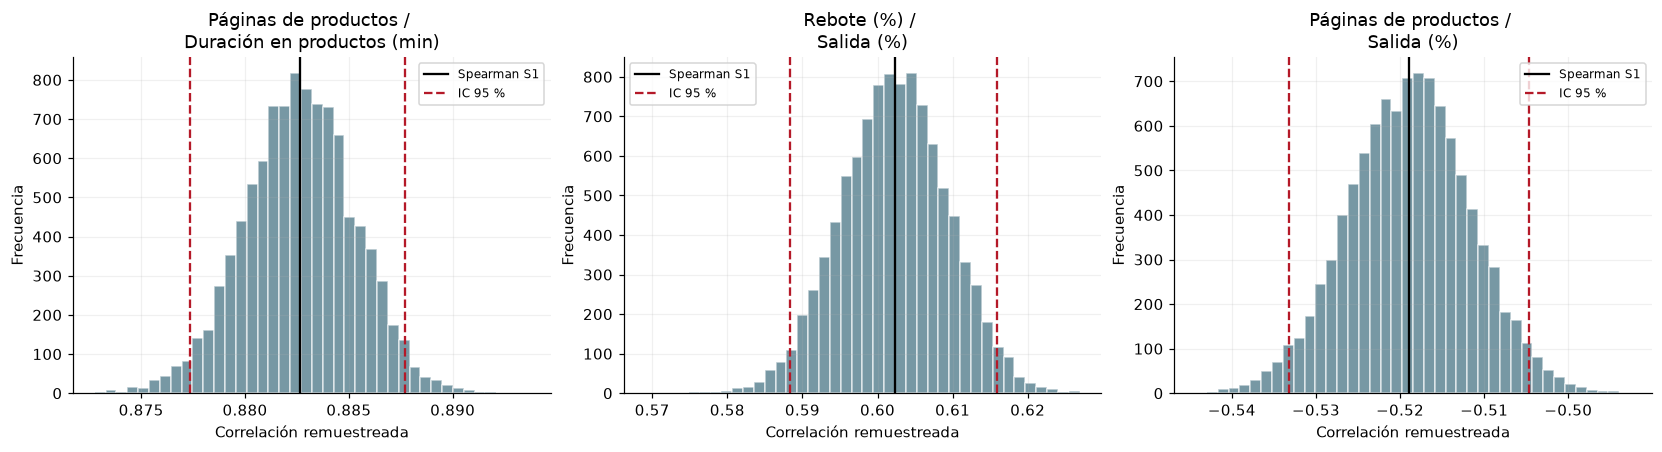

**Figura 3. Distribuciones bootstrap de Spearman; cada panel tiene su propia escala horizontal.** Fuente: elaboración del grupo con datos UCI.

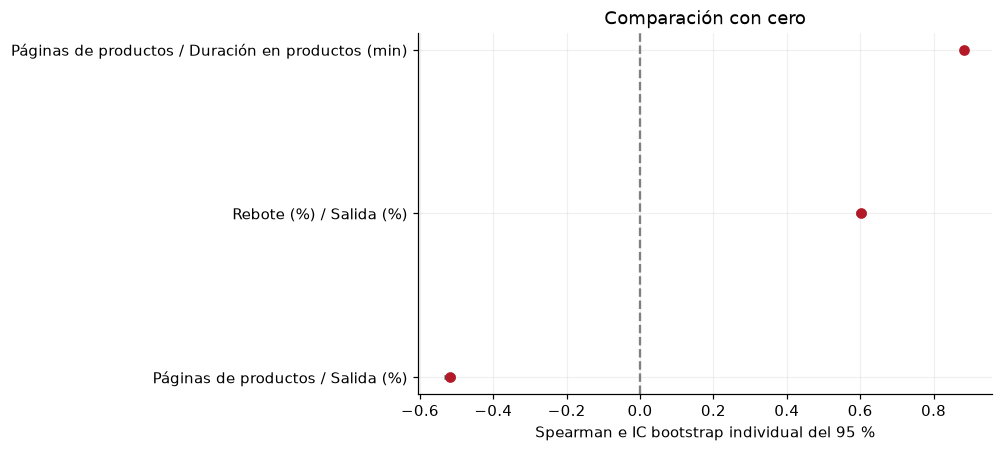

**Figura 4. Intervalos de las tres correlaciones en una escala común.** Fuente: elaboración del grupo con datos UCI.

**Páginas de productos / Duración en productos (min):** ρ = 0,883; IC **[0,877; 0,888]**, amplitud 0,010. El intervalo **no incluye cero**. Esto describe estabilidad muestral bajo el remuestreo; la sección 5 revisa sensibilidad a extremos.

**Rebote (%) / Salida (%):** ρ = 0,602; IC **[0,588; 0,616]**, amplitud 0,027. El intervalo **no incluye cero**. Esto describe estabilidad muestral bajo el remuestreo; la sección 5 revisa sensibilidad a extremos.

**Páginas de productos / Salida (%):** ρ = -0,519; IC **[-0,533; -0,505]**, amplitud 0,028. El intervalo **no incluye cero**. Esto describe estabilidad muestral bajo el remuestreo; la sección 5 revisa sensibilidad a extremos.

In [9]:
fig,axes=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
for ax,((cx,cy),reps) in zip(axes,CORR.items()):
    r=tabla_corr.loc[(tabla_corr.x==cx)&(tabla_corr.y==cy)].iloc[0]
    ax.hist(reps,bins=40,color=COLORES[0],alpha=.65,edgecolor='white')
    ax.axvline(r.rho_S1,color='black',label='Spearman S1')
    ax.axvline(r.IC95_inf,color=COLORES[1],ls='--',label='IC 95 %')
    ax.axvline(r.IC95_sup,color=COLORES[1],ls='--')
    ax.set(title=NOMBRES[cx]+' / '+chr(10)+NOMBRES[cy],xlabel='Correlación remuestreada',ylabel='Frecuencia')
    ax.legend(fontsize=8)
figura('Distribuciones bootstrap de Spearman; cada panel tiene su propia escala horizontal.')
fig,ax=plt.subplots(figsize=(9,4),constrained_layout=True)
for i,r in tabla_corr.iterrows():
    ax.hlines(i,r.IC95_inf,r.IC95_sup,color=COLORES[0],lw=3)
    ax.plot(r.rho_S1,i,'o',color=COLORES[1])
ax.axvline(0,color='gray',ls='--'); ax.set_yticks(range(len(tabla_corr)),tabla_corr.relacion)
ax.set(xlabel='Spearman e IC bootstrap individual del 95 %',title='Comparación con cero'); ax.invert_yaxis()
figura('Intervalos de las tres correlaciones en una escala común.')
for _,r in tabla_corr.iterrows():
    display(Markdown(f'**{r.relacion}:** ρ = {numero(r.rho_S1)}; IC **[{numero(r.IC95_inf)}; '
                     f'{numero(r.IC95_sup)}]**, amplitud {numero(r.amplitud)}. '
                     f'El intervalo **{"incluye" if r.incluye_cero else "no incluye"} cero**. '
                     'Esto describe estabilidad muestral bajo el remuestreo; la sección 5 revisa sensibilidad a extremos.'))

## 4. Monte Carlo basado exclusivamente en parámetros de S1

### 4.1 Modelo, parámetros y datos sintéticos

Se simulan cohortes de sesiones. Cada sesión tiene un tipo de visitante y una compra binaria.
Las proporciones de tipos y las conversiones condicionales provienen **íntegramente de la tabla de S1**.
No se ajustan parámetros nuevos ni se inventan precios, ingresos, efectos de campañas o crecimiento.

**Modelo A, composición aleatoria:** los conteos por tipo siguen una multinomial(N, q); las compras de
cada tipo siguen una binomial(n_g, p_g). Las cohortes son independientes, con q y p constantes.
Esto equivale marginalmente a una binomial(N, Σq_g p_g); se usa esa identidad para validar el código.
**Modelo B, composición fija:** se conserva una cuota por tipo y se suman sus binomiales; permite
evaluar el efecto de condicionar en la composición, no una validación causal del tipo de visitante.

N = 12.330 es el caso principal. N = 100, 500, 1.000 y 5.000 son tamaños hipotéticos de diseño,
como los tamaños de cartera del ejemplo del profesor. Cada escenario utiliza 10.000 cohortes.
Las probabilidades se mantienen fijas: la dispersión simulada es condicional y **no incorpora la
incertidumbre de estimar p y q**. Reproducir una media usada para calibrar el modelo demuestra
coherencia interna, no validación externa de predicciones futuras.

Generamos primero una cohorte de sesiones individuales para hacer explícitos los datos sintéticos.
Para las 10.000 repeticiones utilizamos conteos agregados equivalentes, evitando matrices gigantes.
La validación cubre categorías, valores binarios, composición, conversión y momentos; no se afirma
que se haya reconstruido todo el dataset de navegación de 18 columnas.

In [10]:
t0=perf_counter()
TIPOS=visitantes.index.to_list()
Q=(visitantes.sesiones/BASE['n']).to_numpy(dtype=float)
P=(visitantes.compras/visitantes.sesiones).to_numpy(dtype=float)
P_GLOBAL=float(np.sum(Q*P))
assert np.isclose(P_GLOBAL,BASE['p_compra'],rtol=1e-12)
rng=rng_bloque(400)
g=rng.choice(len(TIPOS),size=BASE['n'],p=Q)
sinteticos=pd.DataFrame({'VisitorType':np.asarray(TIPOS)[g], 'Revenue':rng.random(len(g))<P[g]})
assert sinteticos.VisitorType.isin(TIPOS).all() and sinteticos.Revenue.isin([True,False]).all()
display(sinteticos.head(10))
validacion_sint=sinteticos.groupby('VisitorType').Revenue.agg(n_sintetico='size',compras_sinteticas='sum').reindex(TIPOS)
validacion_sint['proporcion_sintetica']=validacion_sint.n_sintetico/len(sinteticos)
validacion_sint['proporcion_S1']=Q
validacion_sint['conversion_sintetica']=validacion_sint.compras_sinteticas/validacion_sint.n_sintetico
validacion_sint['conversion_S1']=P
tabla(validacion_sint.reset_index(), 'Una cohorte sintética frente a las proporciones de S1 (variación esperable)')

def cuotas_fijas(N,q):
    cuotas=np.floor(N*q).astype(int)
    orden=np.argsort(-(N*q-cuotas))
    cuotas[orden[:N-cuotas.sum()]]+=1
    assert cuotas.sum()==N
    return cuotas

def simular_cohortes(N,B,q,p,rng,fija=False):
    if fija:
        cuotas=cuotas_fijas(N,q)
        grupos=np.broadcast_to(cuotas,(B,len(q)))
        media=float(np.sum(cuotas*p)); var=float(np.sum(cuotas*p*(1-p)))
    else:
        grupos=rng.multinomial(N,q,size=B)
        prob=float(np.sum(q*p)); media=N*prob; var=N*prob*(1-prob)
    compras_grupo=rng.binomial(grupos,p)
    compras=compras_grupo.sum(axis=1)
    assert (compras>=0).all() and (compras<=N).all()
    return compras,grupos,media,var

MC={}; filas_mc=[]
for i,N in enumerate([100,500,1000,5000,BASE['n']]):
    for j,fija in enumerate([False,True]):
        compras,grupos,mu,var=simular_cohortes(N,B_MC,Q,P,rng_bloque(410+2*i+j),fija)
        tasa=compras/N; nombre='Fija' if fija else 'Aleatoria'
        mcse=tasa.std(ddof=1)/np.sqrt(B_MC)
        margen=stats.norm.ppf(.975)*mcse
        # Umbral de referencia: conversión observada S1, no objetivo comercial.
        evento=tasa>=BASE['p_compra']; k=int(evento.sum()); elo,ehi=intervalo_wilson(k,B_MC)
        MC[(N,nombre)]={'compras':compras,'tasas':tasa,'grupos':grupos,'media_teorica':mu,'var_teorica':var}
        filas_mc.append({'N':N,'composicion':nombre,'B':B_MC,'compras_esperadas':mu,'compras_media_MC':compras.mean(),
                         'var_compras_teorica':var,'var_compras_MC':compras.var(ddof=1),
                         'tasa_teorica_%':100*mu/N,'tasa_media_%':tasa.mean()*100,'DE_tasa_pp':tasa.std(ddof=1)*100,
                         'P2_5_tasa_%':np.quantile(tasa,.025)*100,'P97_5_tasa_%':np.quantile(tasa,.975)*100,
                         'MCSE_media_pp':mcse*100,'margen_MC95_pp':margen*100,
                         'p_alcanza_conversion_S1':k/B_MC,'p_evento_MC95_inf':elo,'p_evento_MC95_sup':ehi,
                         'precision_objetivo_cumplida':bool(margen*100<=TOL_MC_PP),
                         'error_vs_teoria_en_MCSE':float((tasa.mean()-mu/N)/mcse)})
tabla_mc=pd.DataFrame(filas_mc)
assert tabla_mc.error_vs_teoria_en_MCSE.abs().lt(6).all(), 'Media inconsistente con la esperanza analítica.'
assert np.allclose(tabla_mc.var_compras_MC,tabla_mc.var_compras_teorica,rtol=.07), 'Dispersión inconsistente.'
tabla(tabla_mc[['N','composicion','compras_esperadas','compras_media_MC','tasa_media_%','DE_tasa_pp',
                'P2_5_tasa_%','P97_5_tasa_%','MCSE_media_pp','precision_objetivo_cumplida']],
      'Cohortes sintéticas: resultados predictivos condicionales y precisión de la media')
tabla(tabla_mc.loc[tabla_mc.N==BASE['n'],['composicion','var_compras_teorica','var_compras_MC',
          'p_alcanza_conversion_S1','p_evento_MC95_inf','p_evento_MC95_sup','error_vs_teoria_en_MCSE']],
      'Caso principal: validación analítica y probabilidad de alcanzar la conversión de referencia')
TIEMPOS['montecarlo']=perf_counter()-t0

,VisitorType,Revenue
0,New_Visitor,False
1,Returning_Visitor,False
2,Returning_Visitor,False
3,Returning_Visitor,True
4,Returning_Visitor,False
5,New_Visitor,False
6,Returning_Visitor,False
7,Returning_Visitor,False
8,Returning_Visitor,False
9,Returning_Visitor,False


**Tabla 7. Una cohorte sintética frente a las proporciones de S1 (variación esperable)**

,VisitorType,n_sintetico,compras_sinteticas,proporcion_sintetica,proporcion_S1,conversion_sintetica,conversion_S1
0,New_Visitor,1720,405,"0,1395","0,1374","0,2355","0,2491"
1,Other,79,12,"0,0064","0,0069","0,1519","0,1882"
2,Returning_Visitor,10531,1397,"0,8541","0,8557","0,1327","0,1393"


**Tabla 8. Cohortes sintéticas: resultados predictivos condicionales y precisión de la media**

,N,composicion,compras_esperadas,compras_media_MC,tasa_media_%,DE_tasa_pp,P2_5_tasa_%,P97_5_tasa_%,MCSE_media_pp,precision_objetivo_cumplida
0,100,Aleatoria,"15,4745","15,4369","15,4369","3,6306","9,0000","23,0000","0,0363",True
1,100,Fija,"15,5183","15,5315","15,5315","3,6100","9,0000","23,0000","0,0361",True
2,500,Aleatoria,"77,3723","77,2643","15,4529","1,6105","12,4000","18,6000","0,0161",True
3,500,Fija,"77,3840","77,2870","15,4574","1,5979","12,4000","18,6000","0,0160",True
4,1000,Aleatoria,"154,7445","154,6525","15,4652","1,1487","13,2000","17,7000","0,0115",True
5,1000,Fija,"154,7071","154,8500","15,4850","1,1273","13,3000","17,7000","0,0113",True
6,5000,Aleatoria,"773,7226","773,4465","15,4689","0,5096","14,4800","16,4800","0,0051",True
7,5000,Fija,"773,7060","773,8920","15,4778","0,5129","14,4600","16,5000","0,0051",True
8,12330,Aleatoria,"1.908,0000","1.908,0107","15,4745","0,3229","14,8418","16,1071","0,0032",True
9,12330,Fija,"1.908,0000","1.907,4413","15,4699","0,3234","14,8500","16,1152","0,0032",True


**Tabla 9. Caso principal: validación analítica y probabilidad de alcanzar la conversión de referencia**

,composicion,var_compras_teorica,var_compras_MC,p_alcanza_conversion_S1,p_evento_MC95_inf,p_evento_MC95_sup,error_vs_teoria_en_MCSE
8,Aleatoria,"1.612,7474","1.585,5861","0,5047","0,4949","0,5145","0,0269"
9,Fija,"1.595,0567","1.589,6193","0,5026","0,4928","0,5124","-1,4013"


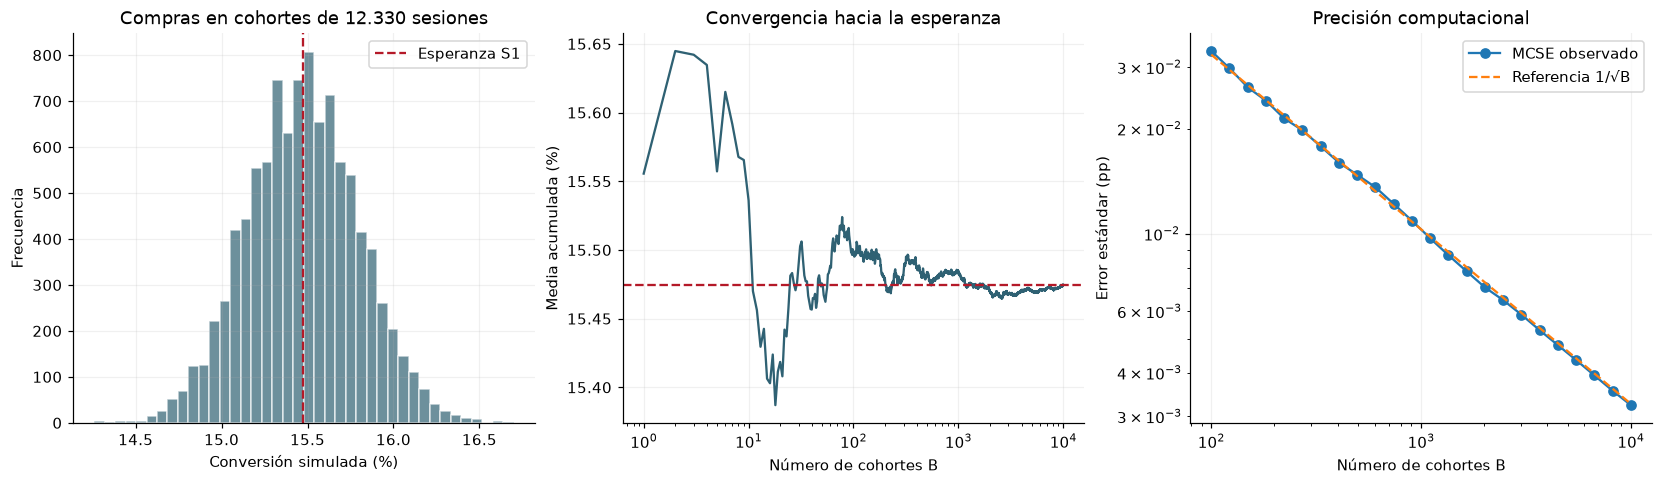

**Figura 5. Distribución predictiva condicional, convergencia y error Monte Carlo; son conceptos diferentes.** Fuente: elaboración del grupo con datos UCI.

**Tabla 10. Precisión al aumentar las repeticiones**

,B,media_%,MCSE_pp,margen95_pp
0,100,"15,4969","0,0334","0,0654"
6,332,"15,4961","0,0178","0,0349"
12,1105,"15,4791","0,0097","0,0190"
18,3674,"15,4684","0,0053","0,0104"
23,10000,"15,4745","0,0032","0,0063"


**Tabla 11. Repeticiones independientes con distintas subsemillas**

,replica,media_%,MCSE_pp
0,1,"15,4742","0,0033"
1,2,"15,4784","0,0032"
2,3,"15,4742","0,0032"
3,4,"15,4730","0,0033"


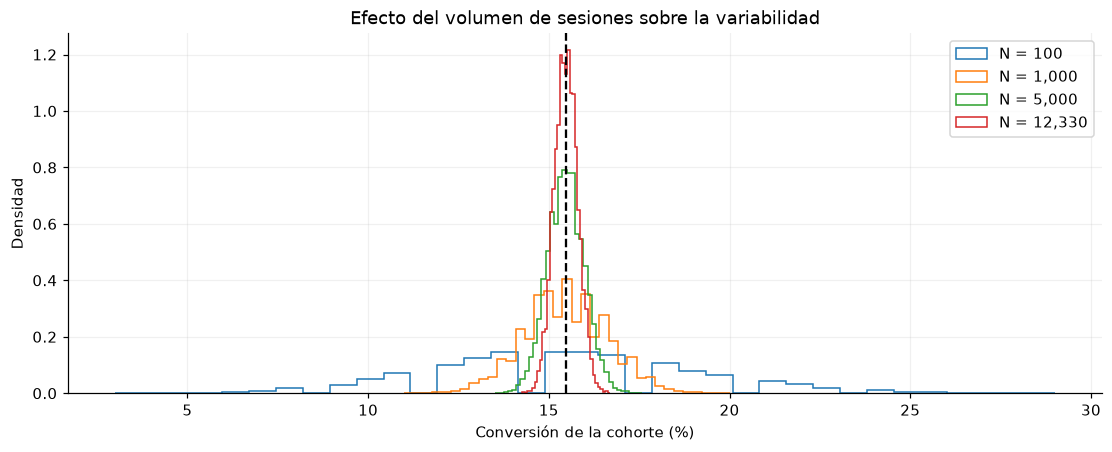

**Figura 6. Distribuciones normalizadas por volumen: aumentar N reduce dispersión de tasas bajo independencia.** Fuente: elaboración del grupo con datos UCI.

**Caso principal:** media **15,475 %**, intervalo predictivo central del 95 % **[14,842; 16,107] %**. MCSE de la media **0,00323 pp**; margen MC del 95 % **0,00633 pp** frente al objetivo de 0.1 pp. La distribución no incorpora cambios de contexto ni incertidumbre de estimación de p y q. Más iteraciones mejoran la precisión de esta media, no estrechan el rango de resultados de una cohorte futura.

**Interpretación comparativa de escenarios.** Con 100 sesiones, el intervalo predictivo central del 95 % es [9,00; 23,00] %, mientras que con 12,330 sesiones es [14,84; 16,11] %. Una tasa de conversión calculada en pocas sesiones puede fluctuar ampliamente aun manteniendo las mismas probabilidades de compra. Bajo estos supuestos, aumentar N reduce esa variación; aumentar B solo mejora la precisión con que describimos la distribución. En el caso principal, la varianza teórica de compras es 1.612,75 con composición aleatoria y 1.595,06 con composición fija: una reducción teórica de 1,10 %. En esta ejecución las varianzas estimadas por Monte Carlo quedan ligeramente en el orden contrario al teórico. Esa fluctuación de las estimaciones no demuestra que fijar la composición aumente la variabilidad: la diferencia teórica es pequeña y dos varianzas muestrales también tienen error Monte Carlo. La comprobación del margen MC de la media no garantiza igual precisión para varianzas, cuantiles o diferencias entre modelos. Para volúmenes pequeños, las cuotas enteras de composición fija pueden además modificar levemente la proporción base al redondear. Para decisiones, conviene considerar el volumen detrás de una tasa antes de interpretar una oscilación como cambio del comportamiento. No se fija un objetivo comercial sin contexto ni se extrapolan estos rangos a otras campañas, períodos o tiendas.

In [11]:
principal=MC[(BASE['n'],'Aleatoria')]
tasas=principal['tasas']; teoria=P_GLOBAL
promedios=np.cumsum(tasas)/np.arange(1,B_MC+1)
ns=np.unique(np.geomspace(100,B_MC,24).astype(int))
convergencia=[]
for k in ns:
    se=tasas[:k].std(ddof=1)/np.sqrt(k)
    convergencia.append({'B':k,'media_%':tasas[:k].mean()*100,'MCSE_pp':se*100,
                        'margen95_pp':1.959963984540054*se*100})
tabla_convergencia=pd.DataFrame(convergencia)
# Réplicas con semillas distintas: diagnóstico independiente, cada una con 10.000 cohortes.
replicas_mc=[]
for i in range(4):
    k,_,mu,var=simular_cohortes(BASE['n'],B_MC,Q,P,rng_bloque(450+i))
    replicas_mc.append({'replica':i+1,'media_%':k.mean()/BASE['n']*100,
                        'MCSE_pp':k.std(ddof=1)/BASE['n']/np.sqrt(B_MC)*100})
tabla_replicas_mc=pd.DataFrame(replicas_mc)
fig,axes=plt.subplots(1,3,figsize=(15,4.3),constrained_layout=True)
axes[0].hist(tasas*100,bins=40,color=COLORES[0],alpha=.7,edgecolor='white')
axes[0].axvline(teoria*100,color=COLORES[1],ls='--',label='Esperanza S1')
axes[0].set(title='Compras en cohortes de 12.330 sesiones',xlabel='Conversión simulada (%)',ylabel='Frecuencia');axes[0].legend()
axes[1].plot(np.arange(1,B_MC+1),promedios*100,color=COLORES[0])
axes[1].axhline(teoria*100,color=COLORES[1],ls='--')
axes[1].set(xscale='log',xlabel='Número de cohortes B',ylabel='Media acumulada (%)',title='Convergencia hacia la esperanza')
axes[2].loglog(tabla_convergencia.B,tabla_convergencia.MCSE_pp,'o-',label='MCSE observado')
axes[2].loglog(ns,np.sqrt(principal['var_teorica'])/BASE['n']/np.sqrt(ns)*100,'--',label='Referencia 1/√B')
axes[2].set(xlabel='Número de cohortes B',ylabel='Error estándar (pp)',title='Precisión computacional'); axes[2].legend()
figura('Distribución predictiva condicional, convergencia y error Monte Carlo; son conceptos diferentes.')
tabla(tabla_convergencia.iloc[[0,6,12,18,-1]], 'Precisión al aumentar las repeticiones')
tabla(tabla_replicas_mc, 'Repeticiones independientes con distintas subsemillas')

fig,ax=plt.subplots(figsize=(10,4),constrained_layout=True)
for i,N in enumerate([100,1000,5000,BASE['n']]):
    ax.hist(MC[(N,'Aleatoria')]['tasas']*100,bins=35,histtype='step',density=True,label=f'N = {N:,}')
ax.axvline(P_GLOBAL*100,color='black',ls='--');ax.legend()
ax.set(xlabel='Conversión de la cohorte (%)',ylabel='Densidad',title='Efecto del volumen de sesiones sobre la variabilidad')
figura('Distribuciones normalizadas por volumen: aumentar N reduce dispersión de tasas bajo independencia.')
r=tabla_mc.loc[(tabla_mc.N==BASE['n'])&(tabla_mc.composicion=='Aleatoria')].iloc[0]
display(Markdown(f'**Caso principal:** media **{numero(r["tasa_media_%"])} %**, intervalo predictivo '
                 f'central del 95 % **[{numero(r["P2_5_tasa_%"])}; {numero(r["P97_5_tasa_%"])}] %**. '
                 f'MCSE de la media **{numero(r.MCSE_media_pp,5)} pp**; margen MC del 95 % '
                 f'**{numero(r.margen_MC95_pp,5)} pp** frente al objetivo de {TOL_MC_PP} pp. '
                 'La distribución no incorpora cambios de contexto ni incertidumbre de estimación de p y q. '
                 'Más iteraciones mejoran la precisión de esta media, no estrechan el rango de resultados de una cohorte futura.'))

pequena=tabla_mc.loc[(tabla_mc.N==100)&(tabla_mc.composicion=='Aleatoria')].iloc[0]
grande=tabla_mc.loc[(tabla_mc.N==BASE['n'])&(tabla_mc.composicion=='Aleatoria')].iloc[0]
fija=tabla_mc.loc[(tabla_mc.N==BASE['n'])&(tabla_mc.composicion=='Fija')].iloc[0]
reduccion_var_teorica_pct=100*(1-fija.var_compras_teorica/grande.var_compras_teorica)
orden_simulado_invertido=bool(fija.var_compras_MC>grande.var_compras_MC)
comparacion_modelos_MC = {
    'N_principal':int(BASE['n']),
    'varianza_teorica_aleatoria':float(grande.var_compras_teorica),
    'varianza_teorica_fija':float(fija.var_compras_teorica),
    'reduccion_varianza_teorica_pct':float(reduccion_var_teorica_pct),
    'varianza_simulada_aleatoria':float(grande.var_compras_MC),
    'varianza_simulada_fija':float(fija.var_compras_MC),
    'orden_simulado_invertido':orden_simulado_invertido}
lectura_orden = (
    'En esta ejecución las varianzas estimadas por Monte Carlo quedan ligeramente en el orden contrario '
    'al teórico. Esa fluctuación de las estimaciones no demuestra que fijar la composición aumente la '
    'variabilidad: la diferencia teórica es pequeña y dos varianzas muestrales también tienen error Monte Carlo. '
    if orden_simulado_invertido else
    'El orden de las varianzas simuladas coincide con el teórico, pero esa coincidencia aislada no '
    'demuestra precisión suficiente para medir una diferencia pequeña entre modelos. ')
interpretacion_montecarlo = (
    f'Con 100 sesiones, el intervalo predictivo central del 95 % es '
    f'[{numero(pequena["P2_5_tasa_%"],2)}; {numero(pequena["P97_5_tasa_%"],2)}] %, '
    f'mientras que con {BASE["n"]:,} sesiones es '
    f'[{numero(grande["P2_5_tasa_%"],2)}; {numero(grande["P97_5_tasa_%"],2)}] %. '
    'Una tasa de conversión calculada en pocas sesiones puede fluctuar ampliamente aun manteniendo '
    'las mismas probabilidades de compra. Bajo estos supuestos, aumentar N reduce esa variación; '
    'aumentar B solo mejora la precisión con que describimos la distribución. '
    f'En el caso principal, la varianza teórica de compras es {numero(grande.var_compras_teorica,2)} '
    f'con composición aleatoria y {numero(fija.var_compras_teorica,2)} con composición fija: '
    f'una reducción teórica de {numero(reduccion_var_teorica_pct,2)} %. ' + lectura_orden +
    'La comprobación del margen MC de la media no garantiza igual precisión para varianzas, '
    'cuantiles o diferencias entre modelos. Para volúmenes pequeños, las cuotas enteras de composición '
    'fija pueden además modificar levemente la proporción base al redondear. '
    'Para decisiones, conviene considerar el volumen detrás de una tasa antes de interpretar '
    'una oscilación como cambio del comportamiento. No se fija un objetivo comercial sin contexto '
    'ni se extrapolan estos rangos a otras campañas, períodos o tiendas.')
display(Markdown('**Interpretación comparativa de escenarios.** '+interpretacion_montecarlo))


### 4.2 Sensibilidad de la mezcla de visitantes

Se varía la proporción de visitantes nuevos al 80 %, 100 % y 120 % de su valor observado en S1.
Se mantiene la proporción de «Other» y se compensa con recurrentes, conservando probabilidades
no negativas que suman uno. Los multiplicadores son **decisiones de escenario**, no parámetros
poblacionales estimados ni efectos de intervención; las conversiones condicionales siguen siendo las de S1.
No se propone que transformar un visitante en nuevo cambie causalmente su probabilidad de compra.
Cada escenario usa 10.000 cohortes y se compara con su expectativa analítica.

**Tabla 12. Sensibilidad a composición con conversiones condicionales fijas de S1**

,multiplicador_nuevos,proporcion_nuevos,conversion_teorica_%,conversion_MC_%,cambio_vs_base_pp,compras_esperadas,P2_5_%,P97_5_%
0,"0,8000","0,1099","15,1728","15,1729","-0,3017","1.870,8027","14,5418","15,8070"
1,"1,0000","0,1374","15,4745","15,4781","0,0000","1.908,0000","14,8418","16,1233"
2,"1,2000","0,1649","15,7761","15,7767","0,3017","1.945,1973","15,1336","16,4152"


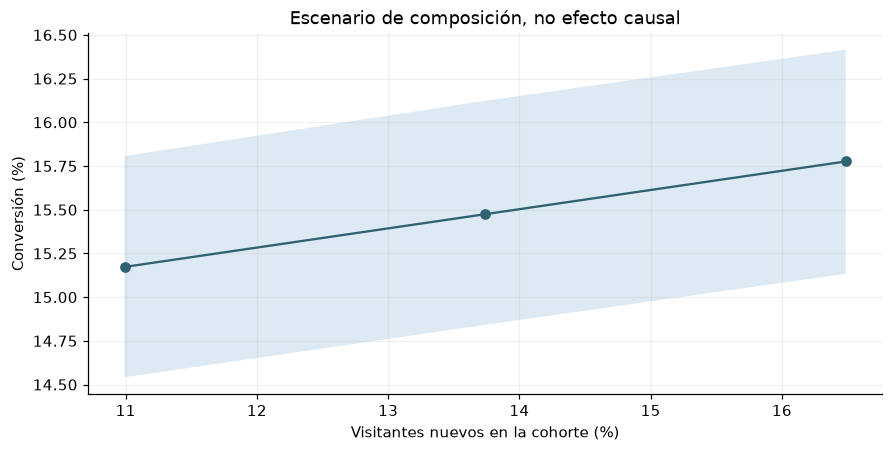

**Figura 7. Cambio de expectativa y rango predictivo condicional al variar la mezcla de visitantes.** Fuente: elaboración del grupo con datos UCI.

**Interpretación del escenario:** pasar del 80 % al 120 % de la proporción base de nuevos cambia la conversión esperada de **15,173 %** a **15,776 %**, manteniendo las tasas de S1. Es una comparación hipotética condicionada; no demuestra el efecto de captar visitantes nuevos.

In [12]:
filas_mezcla=[]
for i,multiplicador in enumerate([.8,1.,1.2]):
    q=Q.copy(); nuevo=TIPOS.index('New_Visitor'); recurrente=TIPOS.index('Returning_Visitor')
    q[nuevo]=Q[nuevo]*multiplicador
    q[recurrente]=Q[recurrente]-(q[nuevo]-Q[nuevo])
    assert (q>=0).all() and np.isclose(q.sum(),1)
    compras,_,mu,var=simular_cohortes(BASE['n'],B_MC,q,P,rng_bloque(470+i))
    tasas=compras/BASE['n']
    filas_mezcla.append({'multiplicador_nuevos':multiplicador,'proporcion_nuevos':q[nuevo],
        'conversion_teorica_%':100*mu/BASE['n'],'conversion_MC_%':100*tasas.mean(),
        'cambio_vs_base_pp':100*(mu/BASE['n']-P_GLOBAL),
        'compras_esperadas':mu,'P2_5_%':100*np.quantile(tasas,.025),'P97_5_%':100*np.quantile(tasas,.975)})
tabla_mezcla=pd.DataFrame(filas_mezcla)
tabla(tabla_mezcla, 'Sensibilidad a composición con conversiones condicionales fijas de S1')
fig,ax=plt.subplots(figsize=(8,4),constrained_layout=True)
ax.plot(tabla_mezcla.proporcion_nuevos*100,tabla_mezcla['conversion_teorica_%'],'o-',color=COLORES[0])
ax.fill_between(tabla_mezcla.proporcion_nuevos*100,tabla_mezcla['P2_5_%'],tabla_mezcla['P97_5_%'],alpha=.15)
ax.set(xlabel='Visitantes nuevos en la cohorte (%)',ylabel='Conversión (%)',title='Escenario de composición, no efecto causal')
figura('Cambio de expectativa y rango predictivo condicional al variar la mezcla de visitantes.')
display(Markdown(f"**Interpretación del escenario:** pasar del 80 % al 120 % de la proporción base de nuevos "
                 f"cambia la conversión esperada de **{numero(tabla_mezcla.iloc[0]['conversion_teorica_%'])} %** "
                 f"a **{numero(tabla_mezcla.iloc[-1]['conversion_teorica_%'])} %**, manteniendo las tasas de S1. "
                 "Es una comparación hipotética condicionada; no demuestra el efecto de captar visitantes nuevos."))


## 5. Robustez, supuestos y observaciones influyentes

### 5.1 Escenarios de valores extremos y filas idénticas

Se recupera la regla de S1: límites globales de 1,5 IQR y 3 IQR, calculados con todas las sesiones
y aplicados por igual a ambos grupos, **por variable**. También se analiza exclusión de filas idénticas.
No se considera ningún escenario una limpieza confirmada ni se escoge el que favorezca una conclusión.

Restringir valores cambia el estimando: la media de sesiones restringidas no es la misma media
poblacional del análisis completo. La mediana y la media recortada al 5 % (en cada cola) son otros
resúmenes y también responden a objetivos diferentes. No se interpretan como estimaciones corregidas
de un mismo parámetro. Se estudia dirección y magnitud; significación constante no implica magnitud robusta.

**Tabla 13. Sensibilidad de medias y diferencias; unidades comunicadas según variable**

,nombre,escenario,n,excluidas,media,mediana,cambio_media_%,diferencia_con_menos_sin,cambio_magnitud_dif_%,direccion_conservada
0,Páginas de productos,Completo,12330,0,"31,7315","18,0000","0,0000","19,4955","0,0000",True
1,Páginas de productos,Sin filas idénticas,12205,125,"32,0456","18,0000","0,9901","19,1598","-1,7222",True
2,Páginas de productos,IQR 1.5,11343,987,"21,6665","16,0000","-31,7192","8,4940","-56,4309",True
3,Páginas de productos,IQR 3,11917,413,"25,6444","17,0000","-19,1831","11,1544","-42,7847",True
4,Duración en productos (min),Completo,12330,0,"19,9124","9,9823","0,0000","13,4370","0,0000",True
5,Duración en productos (min),Sin filas idénticas,12205,125,"20,1164","10,1490","1,0242","13,2205","-1,6111",True
6,Duración en productos (min),IQR 1.5,11369,961,"13,1215","8,6080","-34,1041","6,1982","-53,8720",True
7,Duración en productos (min),IQR 3,11928,402,"15,7728","9,4278","-20,7893","8,3875","-37,5790",True
8,Rebote (%),Completo,12330,0,"2,2191","0,3112","0,0000","-2,0200","0,0000",True
9,Rebote (%),Sin filas idénticas,12205,125,"2,0370","0,2899","-8,2062","-1,8080","-10,4978",True


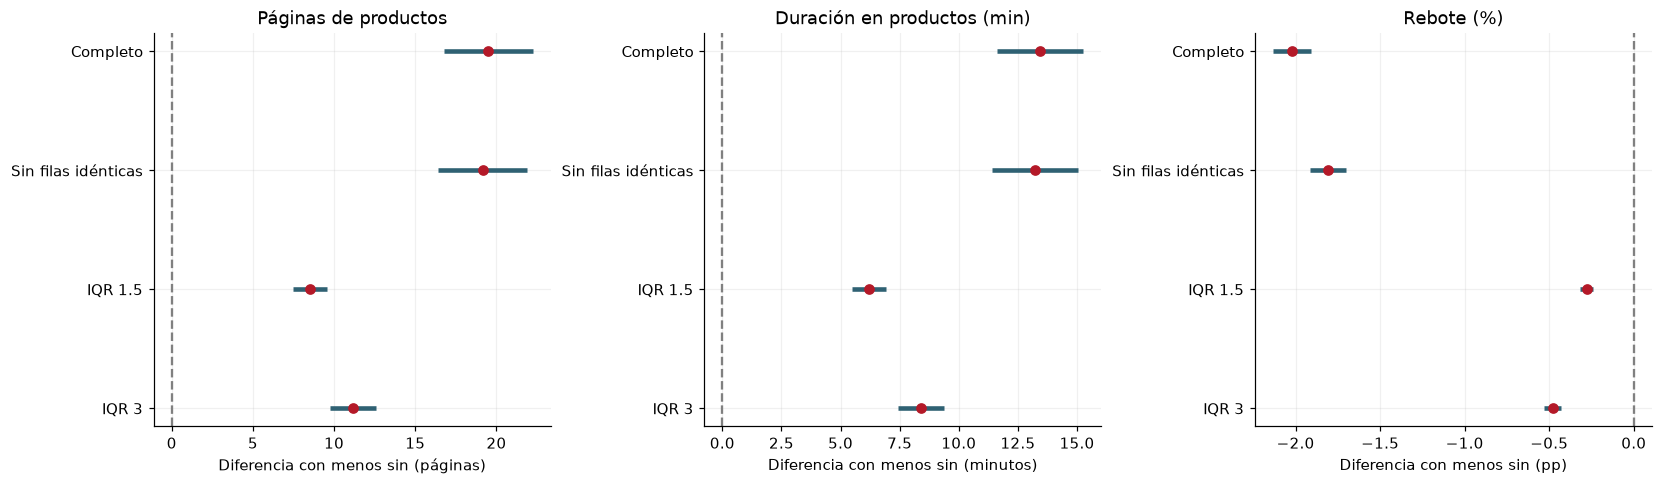

**Figura 8. Sensibilidad de diferencias e IC t individuales diagnósticos; los recortes cambian el estimando.** Fuente: elaboración del grupo con datos UCI.

**Páginas de productos:** con 1,5 IQR la diferencia cambia **-56,43 % en magnitud**; la dirección **se conserva**. Esto debe acompañar cualquier afirmación sobre la diferencia de S1.

**Duración en productos (min):** con 1,5 IQR la diferencia cambia **-53,87 % en magnitud**; la dirección **se conserva**. Esto debe acompañar cualquier afirmación sobre la diferencia de S1.

**Rebote (%):** con 1,5 IQR la diferencia cambia **-86,22 % en magnitud**; la dirección **se conserva**. Esto debe acompañar cualquier afirmación sobre la diferencia de S1.

In [13]:
t0=perf_counter(); filas_rob=[]
for c in PRINCIPALES:
    x=df[c]; q1,q3=x.quantile([.25,.75]); iqr=q3-q1; f=FACTORES[c]
    escenarios=[('Completo',df),('Sin filas idénticas',df.drop_duplicates())]
    for k in [1.5,3.]: escenarios.append((f'IQR {k:g}',df.loc[x.between(q1-k*iqr,q3+k*iqr)]))
    base_dif=(df.loc[df.Revenue,c].mean()-df.loc[~df.Revenue,c].mean())*f
    for nombre,s in escenarios:
        test=stats.ttest_ind(s.loc[s.Revenue,c],s.loc[~s.Revenue,c],equal_var=False)
        intervalo=test.confidence_interval(confidence_level=.95)
        diferencia=(s.loc[s.Revenue,c].mean()-s.loc[~s.Revenue,c].mean())*f
        filas_rob.append({'variable':c,'nombre':NOMBRES[c],'escenario':nombre,'n':len(s),'excluidas':len(df)-len(s),
            'media':s[c].mean()*f,'mediana':s[c].median()*f,'media_recortada_5%':stats.trim_mean(s[c],.05)*f,
            'cambio_media_%':100*(s[c].mean()/df[c].mean()-1),'diferencia_con_menos_sin':diferencia,
            'IC95_dif_inf':intervalo.low*f,'IC95_dif_sup':intervalo.high*f,
            'cambio_magnitud_dif_%':100*(abs(diferencia)/abs(base_dif)-1),
            'direccion_conservada':bool(np.sign(diferencia)==np.sign(base_dif))})
tabla_rob=pd.DataFrame(filas_rob)
tabla(tabla_rob[['nombre','escenario','n','excluidas','media','mediana','cambio_media_%',
                 'diferencia_con_menos_sin','cambio_magnitud_dif_%','direccion_conservada']],
      'Sensibilidad de medias y diferencias; unidades comunicadas según variable')
fig,axes=plt.subplots(1,3,figsize=(15,4.3),constrained_layout=True)
for ax,c in zip(axes,PRINCIPALES):
    sub=tabla_rob.loc[tabla_rob.variable==c].reset_index(drop=True)
    for i,r in sub.iterrows():
        ax.hlines(i,r.IC95_dif_inf,r.IC95_dif_sup,color=COLORES[0],lw=3)
        ax.plot(r.diferencia_con_menos_sin,i,'o',color=COLORES[1])
    ax.axvline(0,color='gray',ls='--');ax.set_yticks(range(len(sub)),sub.escenario);ax.invert_yaxis()
    unidad='pp' if c=='BounceRates' else 'minutos' if 'Duration' in c else 'páginas'
    ax.set(title=NOMBRES[c],xlabel='Diferencia con menos sin ('+unidad+')')
figura('Sensibilidad de diferencias e IC t individuales diagnósticos; los recortes cambian el estimando.')
for c in PRINCIPALES:
    r=tabla_rob.loc[(tabla_rob.variable==c)&(tabla_rob.escenario=='IQR 1.5')].iloc[0]
    display(Markdown(f'**{NOMBRES[c]}:** con 1,5 IQR la diferencia cambia '
                     f'**{numero(r["cambio_magnitud_dif_%"],2)} % en magnitud**; '
                     f'la dirección **{"se conserva" if r.direccion_conservada else "cambia"}**. '
                     'Esto debe acompañar cualquier afirmación sobre la diferencia de S1.'))

### 5.2 Jackknife e influencia individual

Para cada media se calcula el estimador al omitir una sesión: θ_(−i) = (Σx − x_i)/(n−1).
Se informa su error estándar jackknife y las cinco observaciones que más cambian la media.
El cambio se expresa en unidades de la variable y como fracción del SE de S1. Un gran valor
no necesariamente implica gran influencia individual cuando n es grande; muchas observaciones
de cola pueden tener influencia conjunta aunque cada exclusión aislada sea pequeña.

El número de fila CSV incluye la cabecera: índice de pandas + 2. Sirve para revisar registros,
no es un identificador de persona. No se eliminan observaciones porque sean influyentes.

In [14]:
filas_jack=[]; influyentes=[]
for c in PRINCIPALES:
    x=df[c].to_numpy(dtype=float); n=len(x); f=FACTORES[c]
    jack=(x.sum()-x)/(n-1); delta=jack-x.mean()
    se_jack=np.sqrt((n-1)/n*np.sum((jack-jack.mean())**2))
    se_s1=float(base_medias.loc[c,'error_estándar'])
    assert np.isclose(se_jack,se_s1,rtol=1e-9)
    filas_jack.append({'variable':NOMBRES[c],'media':x.mean()*f,'SE_jackknife':se_jack*f,
                      'SE_bootstrap':BOOT[c]['replicas'].std(ddof=1)*f,
                      'max_cambio_individual':np.max(np.abs(delta))*f,
                      'max_cambio_en_SE_S1':np.max(np.abs(delta))/se_s1})
    for idx in np.argsort(-np.abs(delta))[:5]:
        influyentes.append({'variable':c,'fila_CSV':int(idx+2),'valor':float(x[idx]*f),
                            'unidad':NOMBRES[c],'compra':bool(df.Revenue.iloc[idx]),
                            'cambio_media_al_omitir':float(delta[idx]*f),
                            'cambio_en_SE_S1':float(delta[idx]/se_s1)})
tabla_jack=pd.DataFrame(filas_jack); tabla_influyentes=pd.DataFrame(influyentes)
tabla(tabla_jack, 'Jackknife: variabilidad e influencia individual en cada media')
tabla(tabla_influyentes, 'Cinco filas más influyentes por media para investigación del registro')

filas_corr_rob=[]
for cx,cy in PARES:
    base_r=float(BASE['correlaciones_spearman'][cx][cy])
    for nombre,s in [('Completo',df),('Sin filas idénticas',df.drop_duplicates())]:
        rho=stats.spearmanr(s[cx],s[cy]).statistic
        filas_corr_rob.append({'x':cx,'y':cy,'escenario':nombre,'n':len(s),'rho':rho,'cambio_rho':rho-base_r})
    for k in [1.5,3.]:
        mascara=np.ones(len(df),dtype=bool)
        for c in [cx,cy]:
            q1,q3=df[c].quantile([.25,.75]);iqr=q3-q1
            mascara &= df[c].between(q1-k*iqr,q3+k*iqr).to_numpy()
        s=df.loc[mascara];rho=stats.spearmanr(s[cx],s[cy]).statistic
        filas_corr_rob.append({'x':cx,'y':cy,'escenario':f'IQR conjunto {k:g}',
                              'n':len(s),'rho':rho,'cambio_rho':rho-base_r})
tabla_corr_rob=pd.DataFrame(filas_corr_rob)
tabla(tabla_corr_rob, 'Sensibilidad de Spearman a preparación; los recortes restringen ambas variables del par')
TIEMPOS['robustez']=perf_counter()-t0
for cx,cy in PARES:
    sub=tabla_corr_rob.loc[(tabla_corr_rob.x==cx)&(tabla_corr_rob.y==cy)]
    r0=sub.loc[sub.escenario=='Completo'].iloc[0]
    r1=sub.loc[sub.escenario=='IQR conjunto 1.5'].iloc[0]
    display(Markdown(f"**{NOMBRES[cx]} / {NOMBRES[cy]}:** Spearman pasa de **{numero(r0.rho)}** "
                     f"a **{numero(r1.rho)}** al restringir ambas variables, con **{int(r1.n):,} sesiones**. "
                     "La sensibilidad de magnitud debe informarse aunque el IC bootstrap original sea estrecho."))


jack_duracion=tabla_jack.loc[tabla_jack.variable==NOMBRES['ProductRelated_Duration']].iloc[0]
fila_duracion=tabla_influyentes.loc[tabla_influyentes.variable=='ProductRelated_Duration'].iloc[0]
cola_duracion=tabla_rob.loc[(tabla_rob.variable=='ProductRelated_Duration')&(tabla_rob.escenario=='IQR 1.5')].iloc[0]
comparacion_influencia = {
    'fila_CSV_duracion_mas_influyente':int(fila_duracion.fila_CSV),
    'max_cambio_individual_media_min':float(jack_duracion.max_cambio_individual),
    'max_cambio_individual_media_seg':float(jack_duracion.max_cambio_individual*60),
    'max_cambio_individual_en_SE_S1':float(jack_duracion.max_cambio_en_SE_S1),
    'cambio_media_duracion_IQR_pct':float(cola_duracion['cambio_media_%']),
    'cambio_magnitud_diferencia_duracion_IQR_pct':float(cola_duracion['cambio_magnitud_dif_%'])}
interpretacion_jackknife = (
    f'La sesión más influyente para la media de duración es la fila CSV {int(fila_duracion.fila_CSV)}. '
    f'Al omitirla, el cambio absoluto de la media es {numero(jack_duracion.max_cambio_individual,3)} minutos '
    f'({numero(jack_duracion.max_cambio_individual*60,2)} segundos), equivalente a '
    f'{numero(jack_duracion.max_cambio_en_SE_S1,3)} errores estándar de S1. '
    f'En contraste, el escenario 1,5 IQR cambia la media de duración '
    f'{numero(cola_duracion["cambio_media_%"],2)} % y la magnitud de la diferencia entre grupos '
    f'{numero(cola_duracion["cambio_magnitud_dif_%"],2)} %. '
    'La sensibilidad conjunta a las sesiones de cola no se explica solamente por una observación '
    'extraordinaria: muchas exclusiones simultáneas pueden producir cambios relevantes aunque '
    'cada omisión individual cambie poco la media. Jackknife e IQR evalúan preguntas distintas. '
    'El recorte también restringe la población analizada, por lo que no se presenta como una '
    'estimación corregida del mismo parámetro ni como justificación automática para eliminar filas.')
display(Markdown('**Influencia individual frente a sensibilidad conjunta.** '+interpretacion_jackknife))


**Tabla 14. Jackknife: variabilidad e influencia individual en cada media**

,variable,media,SE_jackknife,SE_bootstrap,max_cambio_individual,max_cambio_en_SE_S1
0,Páginas de productos,"31,7315","0,4005","0,3976","0,0546","0,1363"
1,Duración en productos (min),"19,9124","0,2872","0,2878","0,0849","0,2955"
2,Rebote (%),"2,2191","0,0437","0,0429","0,0014","0,0330"


**Tabla 15. Cinco filas más influyentes por media para investigación del registro**

,variable,fila_CSV,valor,unidad,compra,cambio_media_al_omitir,cambio_en_SE_S1
0,ProductRelated,5154,"705,0000",Páginas de productos,False,"-0,0546","-0,1363"
1,ProductRelated,6686,"686,0000",Páginas de productos,False,"-0,0531","-0,1325"
2,ProductRelated,8310,"584,0000",Páginas de productos,False,"-0,0448","-0,1118"
3,ProductRelated,10320,"534,0000",Páginas de productos,True,"-0,0407","-0,1017"
4,ProductRelated,6789,"518,0000",Páginas de productos,False,"-0,0394","-0,0985"
5,ProductRelated_Duration,8073,"1.066,2254",Duración en productos (min),False,"-0,0849","-0,2955"
6,ProductRelated_Duration,5154,"719,5206",Duración en productos (min),False,"-0,0567","-0,1976"
7,ProductRelated_Duration,9240,"499,5078",Duración en productos (min),False,"-0,0389","-0,1354"
8,ProductRelated_Duration,8786,"450,1643",Duración en productos (min),True,"-0,0349","-0,1215"
9,ProductRelated_Duration,8310,"414,0693",Duración en productos (min),False,"-0,0320","-0,1113"


**Tabla 16. Sensibilidad de Spearman a preparación; los recortes restringen ambas variables del par**

,x,y,escenario,n,rho,cambio_rho
0,ProductRelated,ProductRelated_Duration,Completo,12330,"0,8827","0,0000"
1,ProductRelated,ProductRelated_Duration,Sin filas idénticas,12205,"0,8792","-0,0035"
2,ProductRelated,ProductRelated_Duration,IQR conjunto 1.5,11048,"0,8471","-0,0356"
3,ProductRelated,ProductRelated_Duration,IQR conjunto 3,11778,"0,8669","-0,0158"
4,BounceRates,ExitRates,Completo,12330,"0,6023","0,0000"
5,BounceRates,ExitRates,Sin filas idénticas,12205,"0,5894","-0,0129"
6,BounceRates,ExitRates,IQR conjunto 1.5,10747,"0,4052","-0,1971"
7,BounceRates,ExitRates,IQR conjunto 3,11268,"0,4764","-0,1259"
8,ProductRelated,ExitRates,Completo,12330,"-0,5189","0,0000"
9,ProductRelated,ExitRates,Sin filas idénticas,12205,"-0,5042","0,0147"


**Páginas de productos / Duración en productos (min):** Spearman pasa de **0,883** a **0,847** al restringir ambas variables, con **11,048 sesiones**. La sensibilidad de magnitud debe informarse aunque el IC bootstrap original sea estrecho.

**Rebote (%) / Salida (%):** Spearman pasa de **0,602** a **0,405** al restringir ambas variables, con **10,747 sesiones**. La sensibilidad de magnitud debe informarse aunque el IC bootstrap original sea estrecho.

**Páginas de productos / Salida (%):** Spearman pasa de **-0,519** a **-0,379** al restringir ambas variables, con **10,244 sesiones**. La sensibilidad de magnitud debe informarse aunque el IC bootstrap original sea estrecho.

**Influencia individual frente a sensibilidad conjunta.** La sesión más influyente para la media de duración es la fila CSV 8073. Al omitirla, el cambio absoluto de la media es 0,085 minutos (5,09 segundos), equivalente a 0,295 errores estándar de S1. En contraste, el escenario 1,5 IQR cambia la media de duración -34,10 % y la magnitud de la diferencia entre grupos -53,87 %. La sensibilidad conjunta a las sesiones de cola no se explica solamente por una observación extraordinaria: muchas exclusiones simultáneas pueden producir cambios relevantes aunque cada omisión individual cambie poco la media. Jackknife e IQR evalúan preguntas distintas. El recorte también restringe la población analizada, por lo que no se presenta como una estimación corregida del mismo parámetro ni como justificación automática para eliminar filas.

### 5.3 Lectura crítica de los supuestos

- **Datos observacionales:** ni bootstrap ni permutación crean asignación aleatoria; persiste confusión.
- **Dependencia:** los cálculos ordinarios presuponen sesiones razonablemente independientes.
  No hay secuencia temporal detallada ni identificadores para justificar un bootstrap de bloques.
- **Colas:** estimar una media con bootstrap no la vuelve resistente a extremos. IQR y jackknife
  evalúan aspectos complementarios de sensibilidad conjunta e individual.
- **Monte Carlo:** composición fija y aleatoria son supuestos distintos; la segunda equivale a una
  binomial global bajo independencia. La expectativa coincidente es una identidad de calibración.
- **Incertidumbre omitida:** los escenarios condicionan en p y q estimados. Sus rangos no cubren
  incertidumbre de parámetros, cambios de campañas, estacionalidad ni otras tiendas.
- **Datos sintéticos:** aquí representan únicamente tipo de visitante y compra. No aportan nuevas
  sesiones observadas ni validan un modelo de toda la navegación o una garantía de privacidad.
- **Categoría pequeña:** Other contiene solo 85 sesiones originales; su conversión merece cautela,
  aunque una simulación con probabilidades fijas se ejecute con gran precisión.
- **Preparación para modelos:** PageValues no se incluye en la simulación. Antes de predecir compra
  debe revisarse su disponibilidad temporal para evitar filtración de información.

## 6. Resultados validados y recomendaciones para Sumativa 3

«Validado» se usa aquí con alcance limitado: evaluación de coherencia y estabilidad bajo los
métodos aplicados, no certificación causal ni externa. La tabla distingue estabilidad de signo,
sensibilidad de magnitud y condiciones del modelo. No se obliga a encontrar una correlación
inestable si las tres seleccionadas tienen signo estable; se informa lo que efectivamente resulta.

El JSON final conserva valores numéricos sin redondear, unidades, intervalos, semillas, tamaños,
supuestos, hashes, registros influyentes y recomendaciones. No exporta datasets adicionales ni PDF.

In [15]:
sintesis=[]
for c in PRINCIPALES:
    b=BOOT[c]; r=tabla_rob.loc[(tabla_rob.variable==c)&(tabla_rob.escenario=='IQR 1.5')].iloc[0]
    sintesis.append({'resultado':NOMBRES[c]+' — media',
        'evidencia':f'IC t/percentil/BCa comparados con {B_BOOT:,} remuestras; cambio de media con IQR: {numero(r["cambio_media_%"],2)} %.',
        'estado':'Incertidumbre evaluada; magnitud condicionada por las colas',
        'recomendacion_S3':'Comunicar media e IC junto a mediana y sensibilidad; no borrar extremos sin evidencia.'})
for _,r in tabla_perm.iterrows():
    sintesis.append({'resultado':r.variable+' — contraste',
        'evidencia':f'p permutación={r.p_permutacion:.6g}; Holm={r.p_perm_Holm:.6g}; concordancia S1={r.concordancia_S1}.',
        'estado':'Decisión concordante' if r.concordancia_S1 else 'Revisar discrepancia',
        'recomendacion_S3':(
            'Conservar Welch como principal y la permutación estandarizada como comprobación. '
            'Comunicar que la dirección se mantiene, pero la magnitud disminuye más de la mitad '
            'en el escenario 1,5 IQR; no interpretar la diferencia como un efecto causal.')})
# Comparación explícita entre estabilidad del signo y sensibilidad de magnitud.
cambios_maximos={
    (r.x,r.y):float(tabla_corr_rob.loc[(tabla_corr_rob.x==r.x)&(tabla_corr_rob.y==r.y),'cambio_rho'].abs().max())
    for _,r in tabla_corr.iterrows()}
menor_cambio=min(cambios_maximos.values())
clasificacion_correlaciones=[]
for _,r in tabla_corr.iterrows():
    s=tabla_corr_rob.loc[(tabla_corr_rob.x==r.x)&(tabla_corr_rob.y==r.y)]
    recorte=s.loc[s.escenario=='IQR conjunto 1.5'].iloc[0]
    magnitud_max=cambios_maximos[(r.x,r.y)]
    es_menor=np.isclose(magnitud_max,menor_cambio)
    signo_escenarios=bool((np.sign(s.rho)==np.sign(r.rho_S1)).all())
    estado_signo='Signo no resuelto por el IC' if r.incluye_cero else 'Signo estable bajo bootstrap'
    if es_menor:
        lectura_magnitud='Menor cambio diagnóstico entre los tres pares; no invariancia'
        recomendacion=('Destacar la asociación páginas-duración como la de menor sensibilidad de magnitud '
                       'entre estos pares y escenarios; mantener su carácter observacional y sus límites de población.')
    else:
        lectura_magnitud='Magnitud sensible al recorte conjunto de las variables'
        recomendacion=(f'Comunicar la asociación con cautela: rho pasa de {numero(r.rho_S1)} '
                       f'a {numero(recorte.rho)} con 1,5 IQR. No conservar una etiqueta fija de fuerza '
                       'sin informar ese escenario; el recorte cambia las sesiones incluidas.')
    clasificacion_correlaciones.append({'relacion':r.relacion,'rho_S1':float(r.rho_S1),
        'rho_IQR_1_5':float(recorte.rho),'IC95_inf':float(r.IC95_inf),'IC95_sup':float(r.IC95_sup),
        'estabilidad_signo':estado_signo,'signo_conservado_en_escenarios':signo_escenarios,
        'sensibilidad_magnitud':lectura_magnitud,'mayor_cambio_diagnostico_rho':magnitud_max,
        'alcance':'Clasificación descriptiva comparativa; no umbral inferencial ni robustez universal.'})
    sintesis.append({'resultado':r.relacion,
        'evidencia':f'IC=[{r.IC95_inf:.4f}, {r.IC95_sup:.4f}]; rho con 1,5 IQR={recorte.rho:.4f}; mayor cambio={magnitud_max:.4f}.',
        'estado':estado_signo+'; '+lectura_magnitud,
        'recomendacion_S3':recomendacion})
tabla_clasificacion_corr=pd.DataFrame(clasificacion_correlaciones)
tabla(tabla_clasificacion_corr,'Clasificación para S3: estabilidad muestral y sensibilidad de magnitud son dimensiones distintas')
sintesis.append({'resultado':'Compras simuladas',
    'evidencia':f'Rangos predictivos por volumen; reducción teórica de varianza fija={reduccion_var_teorica_pct:.2f} %; fluctuación del orden MC={orden_simulado_invertido}.',
    'estado':'Coherencia interna bajo probabilidades fijas de S1',
    'recomendacion_S3':'Interpretar oscilaciones de conversión según volumen; separar predicción condicional y MCSE. Para comparar varianzas cercanas usar la referencia analítica, no el orden de dos estimaciones Monte Carlo; no afirmar validación externa.'})
tabla_sintesis=pd.DataFrame(sintesis)
tabla(tabla_sintesis, 'Resultados evaluados y recomendaciones concretas para S3')
display(Markdown('**Conclusión:** la validación computacional complementa S1. La inferencia sobre medias '
                 'y las asociaciones deben leerse junto con la influencia de las colas. La simulación '
                 'cuantifica variabilidad bajo escenarios explícitos; su precisión no elimina incertidumbre '
                 'de parámetros o sesgos de los datos. Los hallazgos que se comuniquen en S3 deben conservar estas condiciones.'))

# Controles de entrega: verifican requisitos reales, no sustituyen la revisión del equipo.
assert B_BOOT>=10000 and B_PERM>=10000 and B_MC>=10000 and len(tabla_corr) in [3,4,5]
assert len(tabla_boot)==3 and np.isfinite(tabla_boot.select_dtypes(include='number')).all().all()
assert tabla_mc.precision_objetivo_cumplida.all(), 'No se alcanzó el margen MC objetivo; aumentar B o justificar precisión.'

def registros(tab):
    return tab.to_dict(orient='records')

resultado={
 'schema_version':1,
 'proyecto':'Online Shoppers Purchasing Intention — Grupo 2 — Sumativa 2',
 'generado_UTC':datetime.now(timezone.utc).isoformat(),
 'procedencia':{'S1':BASE['procedencia'],'sha256_csv_verificado':HASH_CSV,
               'notebook_S2':'S2/Validacion_Simulacion.ipynb',
               'referencia_docente':'https://github.com/jpmaidana/MCDI501-202682/tree/main/03-evaluaciones/Sumativa-2-validacion-simulacion-remuestreo'},
 'configuracion':{'semilla_maestra':SEED,'generadores':'SeedSequence([semilla, numero_bloque])',
                  'B_bootstrap':B_BOOT,'B_permutacion':B_PERM,'B_correlaciones':B_CORR,'B_MonteCarlo':B_MC,
                  'alpha':ALPHA,'confianza':CONFIANZA,'margen_MC_objetivo_pp':TOL_MC_PP,
                  'python':sys.version.split()[0],'versiones':versiones,
                  'bloques_semillas':{'bootstrap':[100,101,102],'permutacion':[200,201],
                    'correlaciones':[300,301,302],'sinteticos':400,'cohortes':list(range(410,420)),
                    'replicas_MC':[450,451,452,453],'mezcla':[470,471,472]}},
 'diagnostico_kernel':diagnostico_kernel,
 'unidades':{'ProductRelated':'páginas','ProductRelated_Duration':'minutos','BounceRates':'porcentaje',
             'diferencia_BounceRates':'puntos porcentuales','Spearman':'adimensional',
             'MCSE_y_DE_tasa':'puntos porcentuales'},
 'bootstrap_medias':registros(tabla_boot),'permutaciones':registros(tabla_perm),
 'correlaciones':registros(tabla_corr),'montecarlo':registros(tabla_mc),
 'convergencia':registros(tabla_convergencia),'replicas_MC':registros(tabla_replicas_mc),
 'sensibilidad_mezcla':registros(tabla_mezcla),'validacion_cohorte_sintetica':registros(validacion_sint.reset_index()),
 'robustez':registros(tabla_rob),'jackknife':registros(tabla_jack),
 'observaciones_influyentes':registros(tabla_influyentes),
 'sensibilidad_correlaciones':registros(tabla_corr_rob),'sintesis_S3':registros(tabla_sintesis),
 'clasificacion_correlaciones_S3':registros(tabla_clasificacion_corr),
 'comparacion_modelos_MC':comparacion_modelos_MC,
 'comparacion_influencia_individual_conjunta':comparacion_influencia,
 'interpretaciones':{'bootstrap':interpretacion_bootstrap,'permutacion':interpretacion_permutacion,
                     'MonteCarlo':interpretacion_montecarlo,'jackknife':interpretacion_jackknife},
 'supuestos_y_limites':[
   'Inferencia observacional; no causalidad ni generalización garantizada.',
   'Remuestreo ordinario condicionado a independencia razonable y muestra empírica informativa.',
   'Permutación estandarizada: exactitud bajo intercambiabilidad; aproximación para igualdad de medias heterocedástica.',
   'Recortes IQR y medias recortadas cambian el estimando; no son limpieza confirmada.',
   'Monte Carlo usa probabilidades fijas de S1; no propaga incertidumbre de parámetros ni valida externamente.',
   'Percentiles de cohortes son predictivos condicionales; MCSE mide precisión del promedio simulado.',
   'Datos sintéticos limitados a VisitorType y Revenue; no reconstruyen las 18 variables.',
   'Other contiene 85 sesiones y requiere cautela; tamaños y multiplicadores son diseño de escenario.'],
 'tiempos_segundos':TIEMPOS,
 'revision_humana_pendiente':['Interpretación y acuerdo del equipo','Reproducción en otro equipo','Informe a cargo de compañeros','Revisión y publicación en GitHub','Entrega en Canvas']}
destino=RAIZ/'S2/resultados_validados.json'
destino.write_text(json.dumps(resultado,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
relectura=json.loads(destino.read_text(encoding='utf-8'))
assert relectura['configuracion']['B_bootstrap']>=10000
print('Generado:',destino.relative_to(RAIZ))
print('Tablas:',TABLAS,'| Figuras:',FIGURAS)
display(pd.Series(TIEMPOS,name='Segundos por bloque').to_frame())

**Tabla 17. Clasificación para S3: estabilidad muestral y sensibilidad de magnitud son dimensiones distintas**

,relacion,rho_S1,rho_IQR_1_5,IC95_inf,IC95_sup,estabilidad_signo,signo_conservado_en_escenarios,sensibilidad_magnitud,mayor_cambio_diagnostico_rho,alcance
0,Páginas de productos / Duración en productos (min),"0,8827","0,8471","0,8774","0,8877",Signo estable bajo bootstrap,True,Menor cambio diagnóstico entre los tres pares; no invariancia,"0,0356",Clasificación descriptiva comparativa; no umbral inferencial ni robustez universal.
1,Rebote (%) / Salida (%),"0,6023","0,4052","0,5884","0,6159",Signo estable bajo bootstrap,True,Magnitud sensible al recorte conjunto de las variables,"0,1971",Clasificación descriptiva comparativa; no umbral inferencial ni robustez universal.
2,Páginas de productos / Salida (%),"-0,5189","-0,3795","-0,5331","-0,5047",Signo estable bajo bootstrap,True,Magnitud sensible al recorte conjunto de las variables,"0,1394",Clasificación descriptiva comparativa; no umbral inferencial ni robustez universal.


**Tabla 18. Resultados evaluados y recomendaciones concretas para S3**

,resultado,evidencia,estado,recomendacion_S3
0,Páginas de productos — media,"IC t/percentil/BCa comparados con 10,000 remuestras; cambio de media con IQR: -31,72 %.",Incertidumbre evaluada; magnitud condicionada por las colas,Comunicar media e IC junto a mediana y sensibilidad; no borrar extremos sin evidencia.
1,Duración en productos (min) — media,"IC t/percentil/BCa comparados con 10,000 remuestras; cambio de media con IQR: -34,10 %.",Incertidumbre evaluada; magnitud condicionada por las colas,Comunicar media e IC junto a mediana y sensibilidad; no borrar extremos sin evidencia.
2,Rebote (%) — media,"IC t/percentil/BCa comparados con 10,000 remuestras; cambio de media con IQR: -70,92 %.",Incertidumbre evaluada; magnitud condicionada por las colas,Comunicar media e IC junto a mediana y sensibilidad; no borrar extremos sin evidencia.
3,Páginas de productos — contraste,p permutación=9.999e-05; Holm=0.00019998; concordancia S1=True.,Decisión concordante,"Conservar Welch como principal y la permutación estandarizada como comprobación. Comunicar que la dirección se mantiene, pero la magnitud disminuye más de la mitad en el escenario 1,5 IQR; no interpretar la diferencia como un efecto causal."
4,Duración en productos (min) — contraste,p permutación=9.999e-05; Holm=0.00019998; concordancia S1=True.,Decisión concordante,"Conservar Welch como principal y la permutación estandarizada como comprobación. Comunicar que la dirección se mantiene, pero la magnitud disminuye más de la mitad en el escenario 1,5 IQR; no interpretar la diferencia como un efecto causal."
5,Páginas de productos / Duración en productos (min),"IC=[0.8774, 0.8877]; rho con 1,5 IQR=0.8471; mayor cambio=0.0356.",Signo estable bajo bootstrap; Menor cambio diagnóstico entre los tres pares; no invariancia,Destacar la asociación páginas-duración como la de menor sensibilidad de magnitud entre estos pares y escenarios; mantener su carácter observacional y sus límites de población.
6,Rebote (%) / Salida (%),"IC=[0.5884, 0.6159]; rho con 1,5 IQR=0.4052; mayor cambio=0.1971.",Signo estable bajo bootstrap; Magnitud sensible al recorte conjunto de las variables,"Comunicar la asociación con cautela: rho pasa de 0,602 a 0,405 con 1,5 IQR. No conservar una etiqueta fija de fuerza sin informar ese escenario; el recorte cambia las sesiones incluidas."
7,Páginas de productos / Salida (%),"IC=[-0.5331, -0.5047]; rho con 1,5 IQR=-0.3795; mayor cambio=0.1394.",Signo estable bajo bootstrap; Magnitud sensible al recorte conjunto de las variables,"Comunicar la asociación con cautela: rho pasa de -0,519 a -0,379 con 1,5 IQR. No conservar una etiqueta fija de fuerza sin informar ese escenario; el recorte cambia las sesiones incluidas."
8,Compras simuladas,Rangos predictivos por volumen; reducción teórica de varianza fija=1.10 %; fluctuación del orden MC=True.,Coherencia interna bajo probabilidades fijas de S1,"Interpretar oscilaciones de conversión según volumen; separar predicción condicional y MCSE. Para comparar varianzas cercanas usar la referencia analítica, no el orden de dos estimaciones Monte Carlo; no afirmar validación externa."


**Conclusión:** la validación computacional complementa S1. La inferencia sobre medias y las asociaciones deben leerse junto con la influencia de las colas. La simulación cuantifica variabilidad bajo escenarios explícitos; su precisión no elimina incertidumbre de parámetros o sesgos de los datos. Los hallazgos que se comuniquen en S3 deben conservar estas condiciones.

Generado: S2\resultados_validados.json
Tablas: 18 | Figuras: 8


,Segundos por bloque
referencia,0.091884
bootstrap,1.768970
permutacion,0.537403
correlaciones,5.970726
montecarlo,0.056117
robustez,6.245028


## 7. Revisión de entrega y referencias

- [x] Se usan resultados propios de S1, verificados con archivos y cifras de referencia.
- [x] Tres parámetros con 10.000 remuestras, IC percentil y BCa y comparación clásica.
- [x] Dos contrastes con 10.000 permutaciones, distribución nula y discusión de supuestos.
- [x] Tres Spearman con IC y distribuciones bootstrap del 95 %.
- [x] Monte Carlo con 10.000 iteraciones por escenario, datos sintéticos, validación y convergencia.
- [x] Sensibilidad a extremos, filas idénticas, influencia individual y supuestos del modelo.
- [x] Archivo de resultados validados para S3 generado por código.
- [ ] El equipo revisó y puede explicar los métodos e interpretaciones.
- [ ] Se reprodujo el notebook en otro equipo y se verificó el acceso del docente a GitHub.
- [ ] Los compañeros redactaron y revisaron el PDF de máximo 7 páginas; cifras coherentes con este notebook.
- [ ] Se entregaron PDF, ipynb y enlace en Canvas. La ejecución no realiza estas acciones.

### Referencias
1. Sakar, C. y Kastro, Y. (2018). Online Shoppers Purchasing Intention. UCI. https://doi.org/10.24432/C5F88Q
2. Maidana, J. P. (2026). Apuntes y tutoriales de semana 2: aleatoriedad, Monte Carlo, convergencia, bootstrap y sensibilidad. MCDI501, UNAB.
3. Maidana, J. P. Ejemplo Sumativa 2, Give Me Some Credit. Se adapta la estructura; no sus datos, cifras o conclusiones.
   https://github.com/jpmaidana/MCDI501-202682/tree/main/03-evaluaciones/Sumativa-2-validacion-simulacion-remuestreo
4. Efron, B. (1987). Better bootstrap confidence intervals. https://doi.org/10.1080/01621459.1987.10478410
5. SciPy. Bootstrap: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html
6. SciPy. Permutation test y corrección de p aleatorios: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html
7. SciPy. Spearman: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html
8. NumPy. Generadores locales: https://numpy.org/doc/stable/reference/random/generator.html
9. Instrucciones y rúbrica Sumativa 2, fase 3, MCDI501 (Canvas, octubre de 2026).